# The Test Simulations

Mera's test suite runs on small RAMSES simulations whose correct answers are known for reasons
that have nothing to do with Mera: an analytic law, numbers published by the RAMSES developers, or
an input file written by hand. They are public, so anyone can rerun the checks, and they make good
first data to try Mera on.

This page gives each of them the first look Mera gives any simulation, [`quicklook`](@ref), with
nothing tuned to the run. Where that first look misses what a simulation is about, a few
[report cards](report.md) chosen for it follow.

| simulation | what it covers | known answer | checked for |
|---|---|---|---|
| `sedov3d_amr` | hydrodynamics on an adaptive grid, 8 domains | Sedov–Taylor blast, R ∝ t^(2/5); RAMSES reference | physics, periodic geometry, RAMSES files |
| `sedov3d_bisection` | the same blast, domains cut by a tree | every rank's file rebuilt exactly | RAMSES files, MPI rank layouts |
| `sedov3d_iogroups` | files in IO-group folders | every rank's file found and rebuilt | reading, RAMSES files |
| `sedov3d_grav_part` | gravity and tracer particles | tracer count and mass conserved | reading, periodic geometry |
| `dm_gas3d_bisection` | gas, gravity and 30 000 dark-matter particles | the particle count of the input file | RAMSES files, MPI rank layouts |
| `sinks3d` | a sink: an accreting point mass | its mass grows between snapshots | sinks, Mera files |
| `ramses_smbh_bondi` | RAMSES test `sink/smbh-bondi`, unchanged | 40 published numbers | published reference |
| `mhdtube3d` | MHD, 11 hydro variables | ∇·B = 0 forces Bx ≡ 1 | physics, magnetic fields |
| `ramses_abc_flow` | RAMSES test `mhd/abc-flow`, unchanged | 22 published numbers | published reference |
| `stromgren3d` | radiative transfer and ionisation | the Strömgren ionisation front | physics, RT composition |
| `ramses_rt_dirac` | RAMSES test `rt/rt-dirac` (RT with MHD), unchanged | 25 published numbers | published reference, RT columns |
| `cosmo3d` | a cosmological run: gas, dark matter, gravity | every rank's file rebuilt exactly | RAMSES files, cosmology |

Each simulation below lists its known answer, the test files that check it (with what they
check) and the other documentation pages that use it. "RAMSES files" means Mera's RAMSES writer
(`writeramses`, `repartition`): it reads the run, writes it out again, also for a different number
of MPI ranks, and compares with what RAMSES wrote.

Three more simulations in the release serve the test suite only: a Mera file, the 2017 particle
format and the clump-finder test. The release README describes all of them in detail.

**Units.** `quicklook` picks physical units that suit each run. The larger runs read in kpc, M⊙ and
cm⁻³. Several tests keep RAMSES's default units (1 cm, 1 g/cm³, 1 s), so they read in cm, g and
g/cm³: a blast in a box of half a centimetre is what those numbers describe.

## Setup

[`download_testdata`](@ref) fetches all of them (about 300 MB) and returns the folder.

In [1]:
# Example-data root. Point this at your own copy, or set the MERA_EXAMPLES environment variable.
MERA_EXAMPLES = get(ENV, "MERA_EXAMPLES", "/Volumes/FASTStorage/Simulations/Mera-Tests");
TESTDATA = joinpath(MERA_EXAMPLES, "RAMSES-PUBLIC")   # or: TESTDATA = download_testdata()

using Mera, CairoMakie
CairoMakie.activate!()
sim(name) = joinpath(TESTDATA, name)

# quicklook, noting how long it took for the table at the end of the page
TIMES = Tuple{String,Float64,Int}[]
function look(output, name)
    t = @elapsed q = quicklook(output; path=sim(name))
    push!(TIMES, (name, t, q.summary.ncells)); q
end;


*__   __ _______ ______   _______ 


|  |_|  |       |    _ | |   _   |
|       |    ___|   | || |  |_|  |
|       |   |___|   |_||_|       |
|       |    ___|    __  |       |
| ||_|| |   |___|   |  | |   _   |
|_|   |_|_______|___|  |_|__| |__|
Mera v1.9.0 | Julia 1.12.7 | 8 threads



## Hydrodynamics and the grid

### `sedov3d_amr`: a blast wave

A point explosion in uniform gas. The shock radius grows as t^(2/5) (Sedov–Taylor), which the test
suite checks across the seven snapshots. The explosion sits at the box origin. The run's namelist
leaves the box periodic, so `quicklook` shifts its maps across the box edge to show the blast whole
in the middle; the axes keep the true positions, now running from −0.25 to 0.25 cm.

The blast is not symmetric in the maps, and that is in the data: RAMSES refined the part next to the
origin up to level 6, but the parts across the box edges only to levels 4 and 5, so the shell there
is coarser and weaker.

- **Known answer.** **Analytic:** the Sedov–Taylor law R ∝ t^(2/5) across seven snapshots. **Published:** the 13 numbers of RAMSES's own `hydro/sedov3d` reference solution. **Periodic geometry:** regions, profiles and covering grids that wrap across the box faces.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 38](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/38_report_tests.jl): quicklook and report; [test 82](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/82_loadall_tests.jl): loading every data type at once; [test 47](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/47_benchmark_tests.jl): the benchmark tools; [test 78](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/78_download_testdata_tests.jl): download_testdata
- **Docs.** [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md), [Run Your Own Benchmarks](benchmarks/run_your_own.md)

[Mera]: quicklook output 7, reading gas: 2026-10-27T12:51:52.700



   8 CPU file(s), levels 4-7 of 7  (full resolution)


Processing files:  62%|███████████████████████████████▎                  |  ETA: 0:00:00 (58.90 ms/it)

Processing files: 100%|██████████████████████████████████████████████████| Time: 0:00:00 (55.43 ms/it)



✓ File processing complete! Combining results...


   projecting 3 gas map(s) [z, x, y] and the phase diagram from 7071 cells


┌─ Mera quicklook ── output 7 (RAMSES) ───────────────


│ box        : 0.5 cm      levels 4–7  (finest 0.003906 cm)
│ grid       : ndim 3 · ncpu 8 · nvarh 5 · periodic box
│ maps       : shifted across the periodic box to centre the structure
│ time       : 0.009912 s
│ read       : 7071 cells  (full resolution)
│ gas mass   : 0.125 g
│ ρ range    : 0.05543 … 2.661 g/cm³
│ T range    : 1.582e-13 … 1.325e-6 K
└─ 6.33 s ──────────────────────────────────
[Mera]: quicklook output 7 finished: 2026-10-27T12:51:58.829



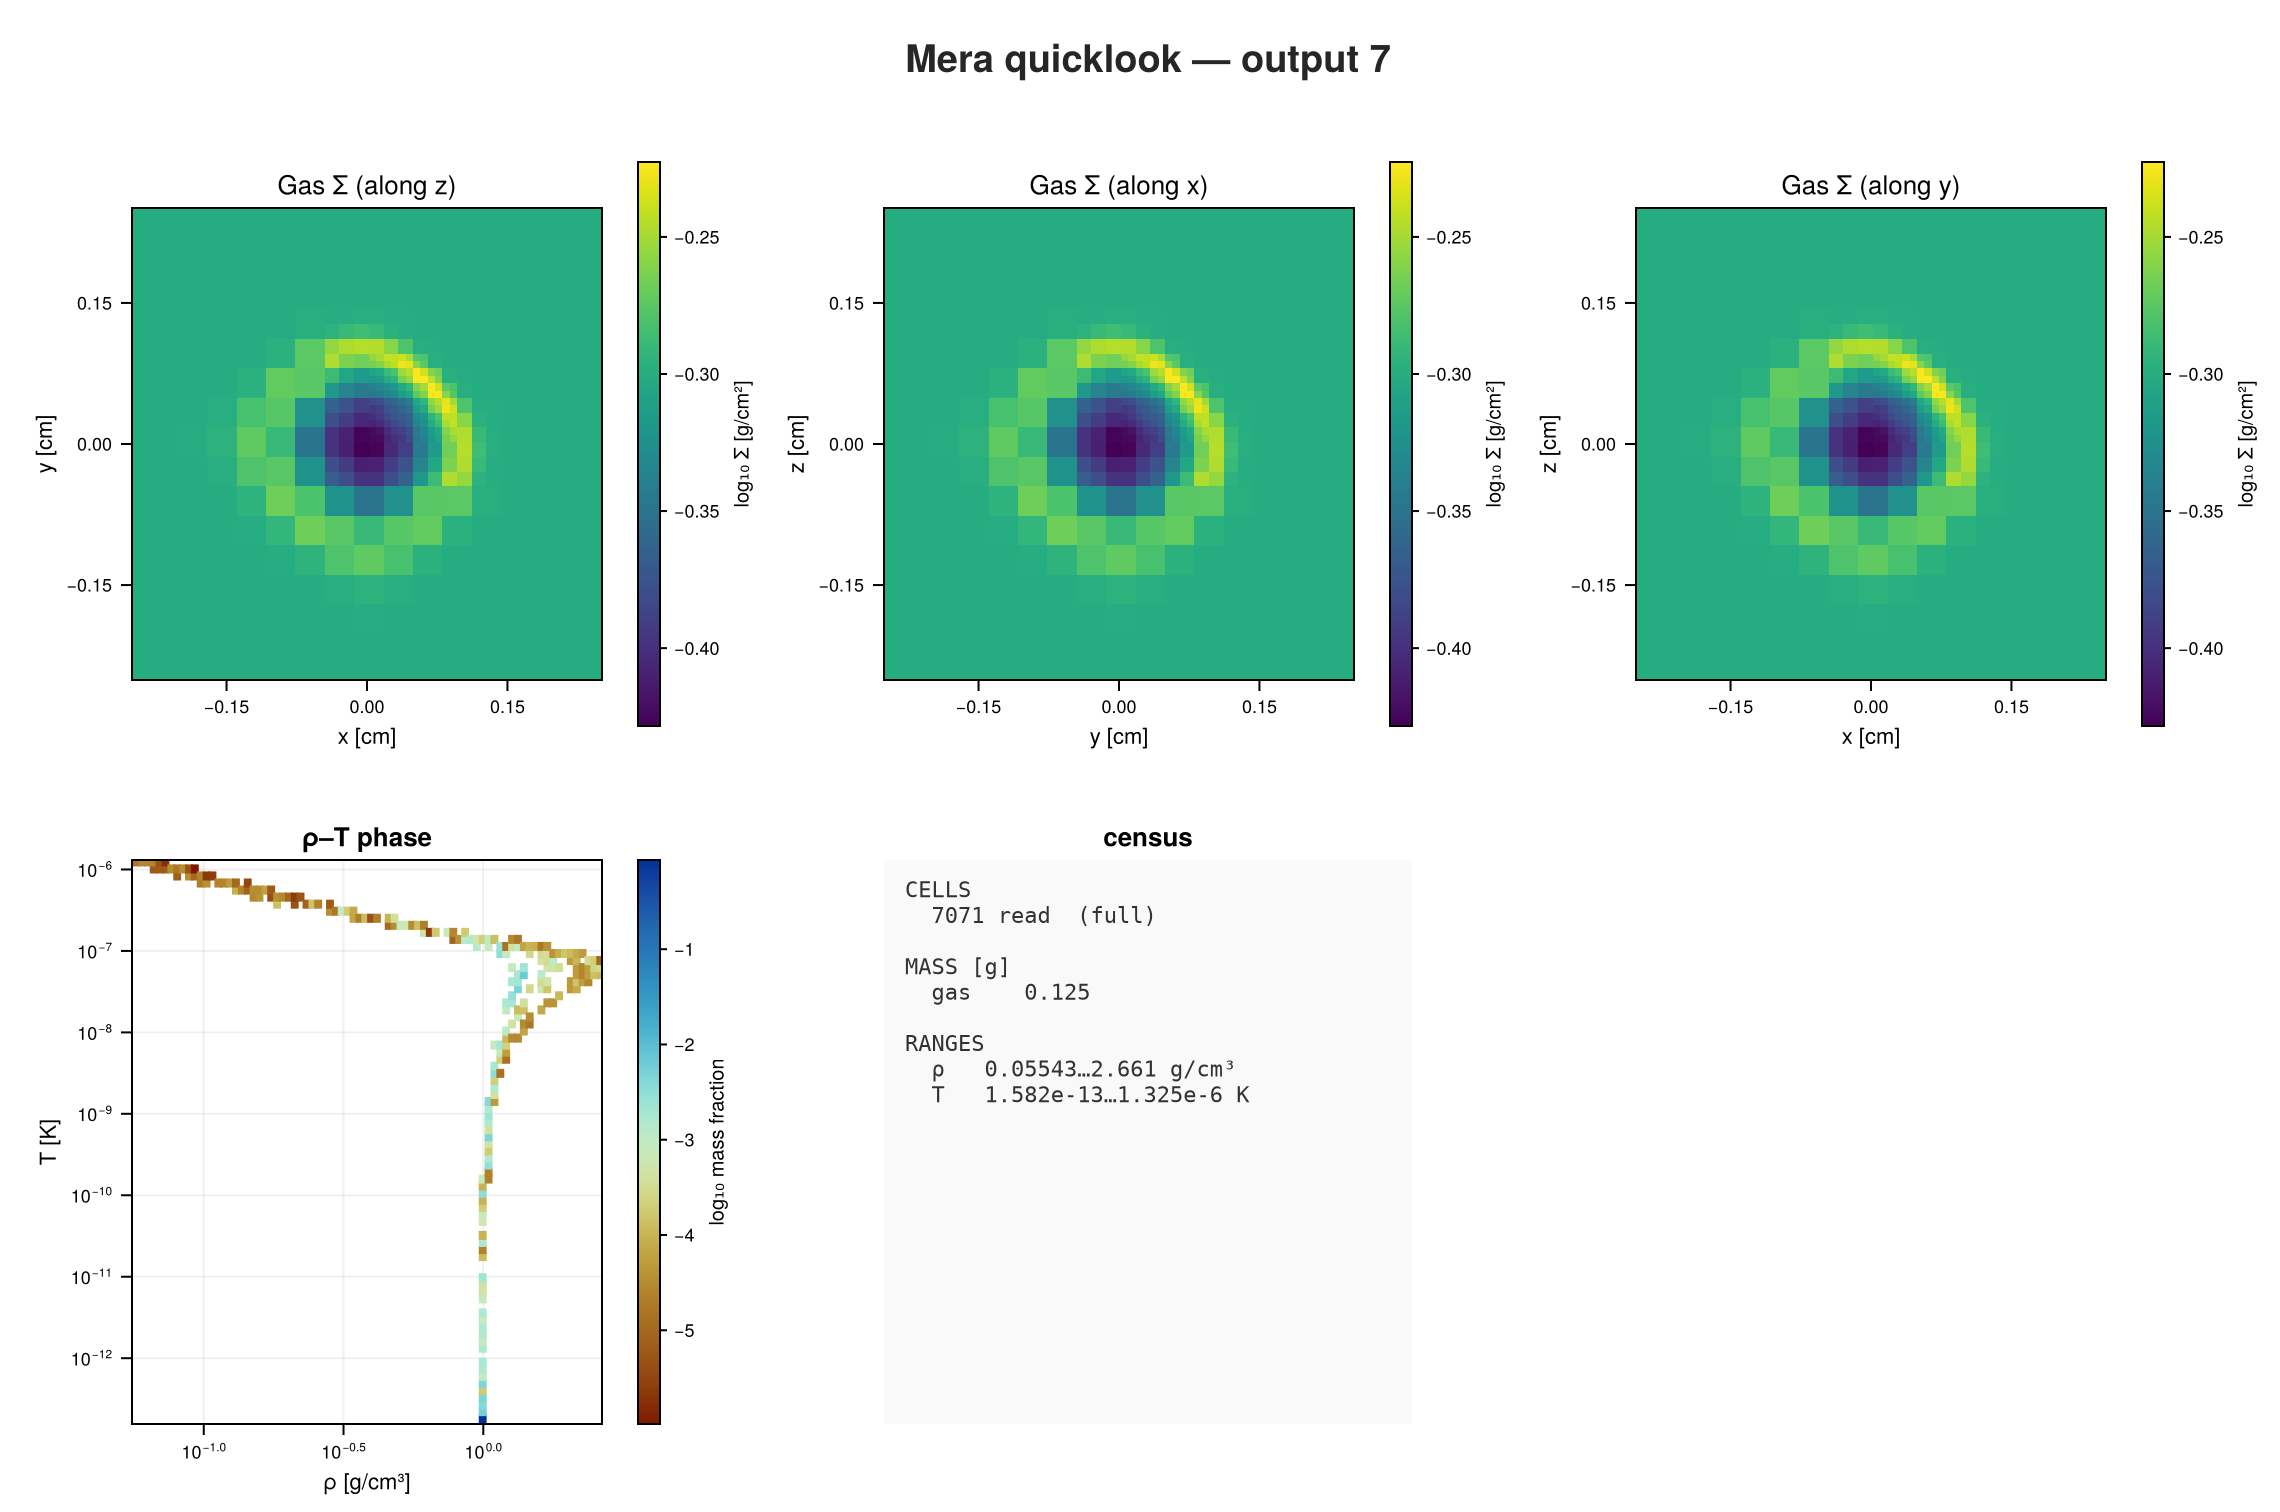

In [2]:
q = look(7, "sedov3d_amr")
quicklookplot(q)

The default report centres its profile on the box, which here is far from the blast. Cards chosen
for this run measure the radius from the origin, where the explosion started, as the shortest
distance in the periodic box (`:r_sphere_periodic`), so the four corners count as one blast. The
phase diagram plots density against pressure: the shocked shell is dense and at high pressure, the
hot interior thin.

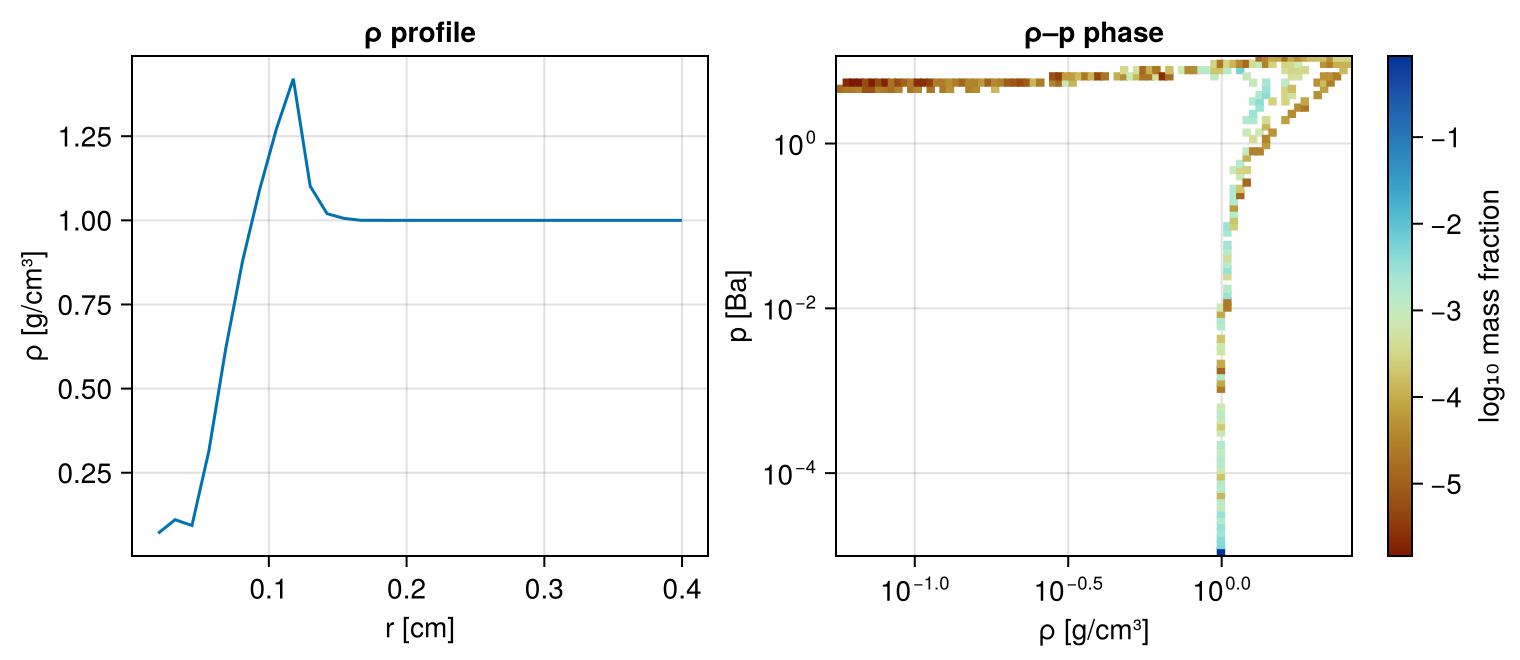

In [3]:
rep = report(7; path=sim("sedov3d_amr"), output=:none, cards=[
    ProfileCard(:hydro, :r_sphere_periodic, :rho; geometry=:spherical, center=[0.0, 0.0, 0.0],
                range_unit=:cm, xunit=:cm, unit=:g_cm3, nbins=32, yscale=:identity),
    PhaseCard(:hydro, :rho, :p; xunit=:g_cm3, yunit=:Ba)])
render(rep, :plot; ncols=2)

### `sedov3d_bisection`: the same blast, cut differently

The same explosion, but RAMSES splits the box among its processes with a tree (`bisection`)
instead of the Hilbert curve. The reader has to follow a different file layout; the numbers agree
with `sedov3d_amr` to the last digit.

- **Known answer.** **RAMSES files, bisection ordering:** Mera rebuilds every rank's file from the stored domain tree exactly, and rewrites the run for other numbers of MPI ranks without changing a value.
- **Test suite.** [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks
- **Docs.** [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

In [4]:
look(7, "sedov3d_bisection");

[Mera]: quicklook output 7, reading gas: 2026-10-27T12:52:17.054

   4 CPU file(s), levels 4-7 of 7  (full resolution)

✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 7071 cells


┌─ Mera quicklook ── output 7 (RAMSES) ───────────────
│ box        : 0.5 cm      levels 4–7  (finest 0.003906 cm)
│ grid       : ndim 3 · ncpu 4 · nvarh 5 · periodic box
│ maps       : shifted across the periodic box to centre the structure
│ time       : 0.009912 s
│ read       : 7071 cells  (full resolution)
│ gas mass   : 0.125 g
│ ρ range    : 0.05543 … 2.661 g/cm³
│ T range    : 1.582e-13 … 1.325e-6 K
└─ 0.13 s ──────────────────────────────────
[Mera]: quicklook output 7 finished: 2026-10-27T12:52:17.174



### `sedov3d_iogroups`: files in IO groups

RAMSES can group its files into folders, one per few processes (`IOGROUPSIZE`): here
`group_00001/` holds the files of ranks 1 and 2 and the files written once per output,
`group_00002/` those of ranks 3 and 4. The readers find each rank's folder themselves.

- **Known answer.** **RAMSES files in IO groups:** every rank's file is found in its group folder and rebuilt exactly from the stored domain walls; the output reads like a plain one (full box volume, conserved mass).
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks
- **Docs.** [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

In [5]:
look(3, "sedov3d_iogroups");

[Mera]: quicklook output 3, reading gas: 2026-10-27T12:52:17.181

   4 CPU file(s), levels 4-7 of 7  (full resolution)

✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 6469 cells


┌─ Mera quicklook ── output 3 (RAMSES) ───────────────
│ box        : 0.5 cm      levels 4–7  (finest 0.003906 cm)
│ grid       : ndim 3 · ncpu 4 · nvarh 5 · periodic box
│ maps       : shifted across the periodic box to centre the structure
│ time       : 0.002422 s
│ read       : 6469 cells  (full resolution)
│ gas mass   : 0.125 g
│ ρ range    : 0.174 … 2.043 g/cm³
│ T range    : 1.582e-13 … 2.467e-6 K
└─ 0.12 s ──────────────────────────────────
[Mera]: quicklook output 3 finished: 2026-10-27T12:52:17.292



## Gravity and particles

### `sedov3d_grav_part`: tracer particles

The blast again, with self-gravity and 124 990 tracer particles that move with the gas. Tracers
carry no mass of their own; the dashboard counts them separately.

- **Known answer.** **Input file:** tracer count and mass conserved exactly. **Reading:** gravity and particles from the same output. **Periodic geometry:** regions that wrap, on particle data.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 38](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/38_report_tests.jl): quicklook and report; [test 82](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/82_loadall_tests.jl): loading every data type at once
- **Docs.** [Data Inspection: Particles](01_particles_First_Inspection.md), [Subregions: Particles](03_particles_Get_Subregions.md), [Mask/Filter/Meta](05_multi_Masking_Filtering.md), [Movies](movie.md), [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

In [6]:
look(7, "sedov3d_grav_part");

[Mera]: quicklook output 7, reading gas: 2026-10-27T12:52:17.300

   8 CPU file(s), levels 4-7 of 7  (full resolution)

✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 7071 cells


[Mera]: quicklook output 7, reading particles: 2026-10-27T12:52:17.423



┌─ Mera quicklook ── output 7 (RAMSES) ───────────────


│ box        : 0.5 cm      levels 4–7  (finest 0.003906 cm)
│ grid       : ndim 3 · ncpu 8 · nvarh 5 · periodic box
│ maps       : shifted across the periodic box to centre the structure
│ time       : 0.009912 s
│ particles  : 124990 total  —  stars 0 · DM 0 · tracers 124990
│ read       : 7071 cells  (full resolution)
│ gas mass   : 0.125 g
│ ρ range    : 0.05542 … 2.661 g/cm³
│ T range    : 1.582e-13 … 1.325e-6 K
└─ 4.04 s ──────────────────────────────────
[Mera]: quicklook output 7 finished: 2026-10-27T12:52:21.331



### `dm_gas3d_bisection`: gas and dark matter

Gas and 30 000 dark-matter particles under self-gravity, collapsing to the centre. The gas mass of
0.1 g and the dark-matter mass of 1 g are the round numbers of the initial conditions.

- **Known answer.** **RAMSES files with particles:** the particle count is the input file's, and every rank's file of a bisection-ordered run with gravity is rebuilt exactly.
- **Test suite.** [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks
- **Docs.** [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 4, reading gas: 2026-10-27T12:52:21.346

   4 CPU file(s), levels 5-7 of 7  (full resolution)

✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 52466 cells


[Mera]: quicklook output 4, reading particles: 2026-10-27T12:52:21.519



┌─ Mera quicklook ── output 4 (RAMSES) ───────────────
│ box        : 1 cm      levels 5–7  (finest 0.007812 cm)
│ grid       : ndim 3 · ncpu 4 · nvarh 5 · periodic box
│ time       : 0.06128 s
│ particles  : 30000 total  —  stars 0 · DM 30000
│ read       : 52466 cells  (full resolution)
│ gas mass   : 0.1 g
│ ρ range    : 0.09493 … 6.139 g/cm³
│ T range    : 1.545e-9 … 9.866e-8 K
│ part. mass : DM 1 g
└─ 2.49 s ──────────────────────────────────
[Mera]: quicklook output 4 finished: 2026-10-27T12:52:23.831



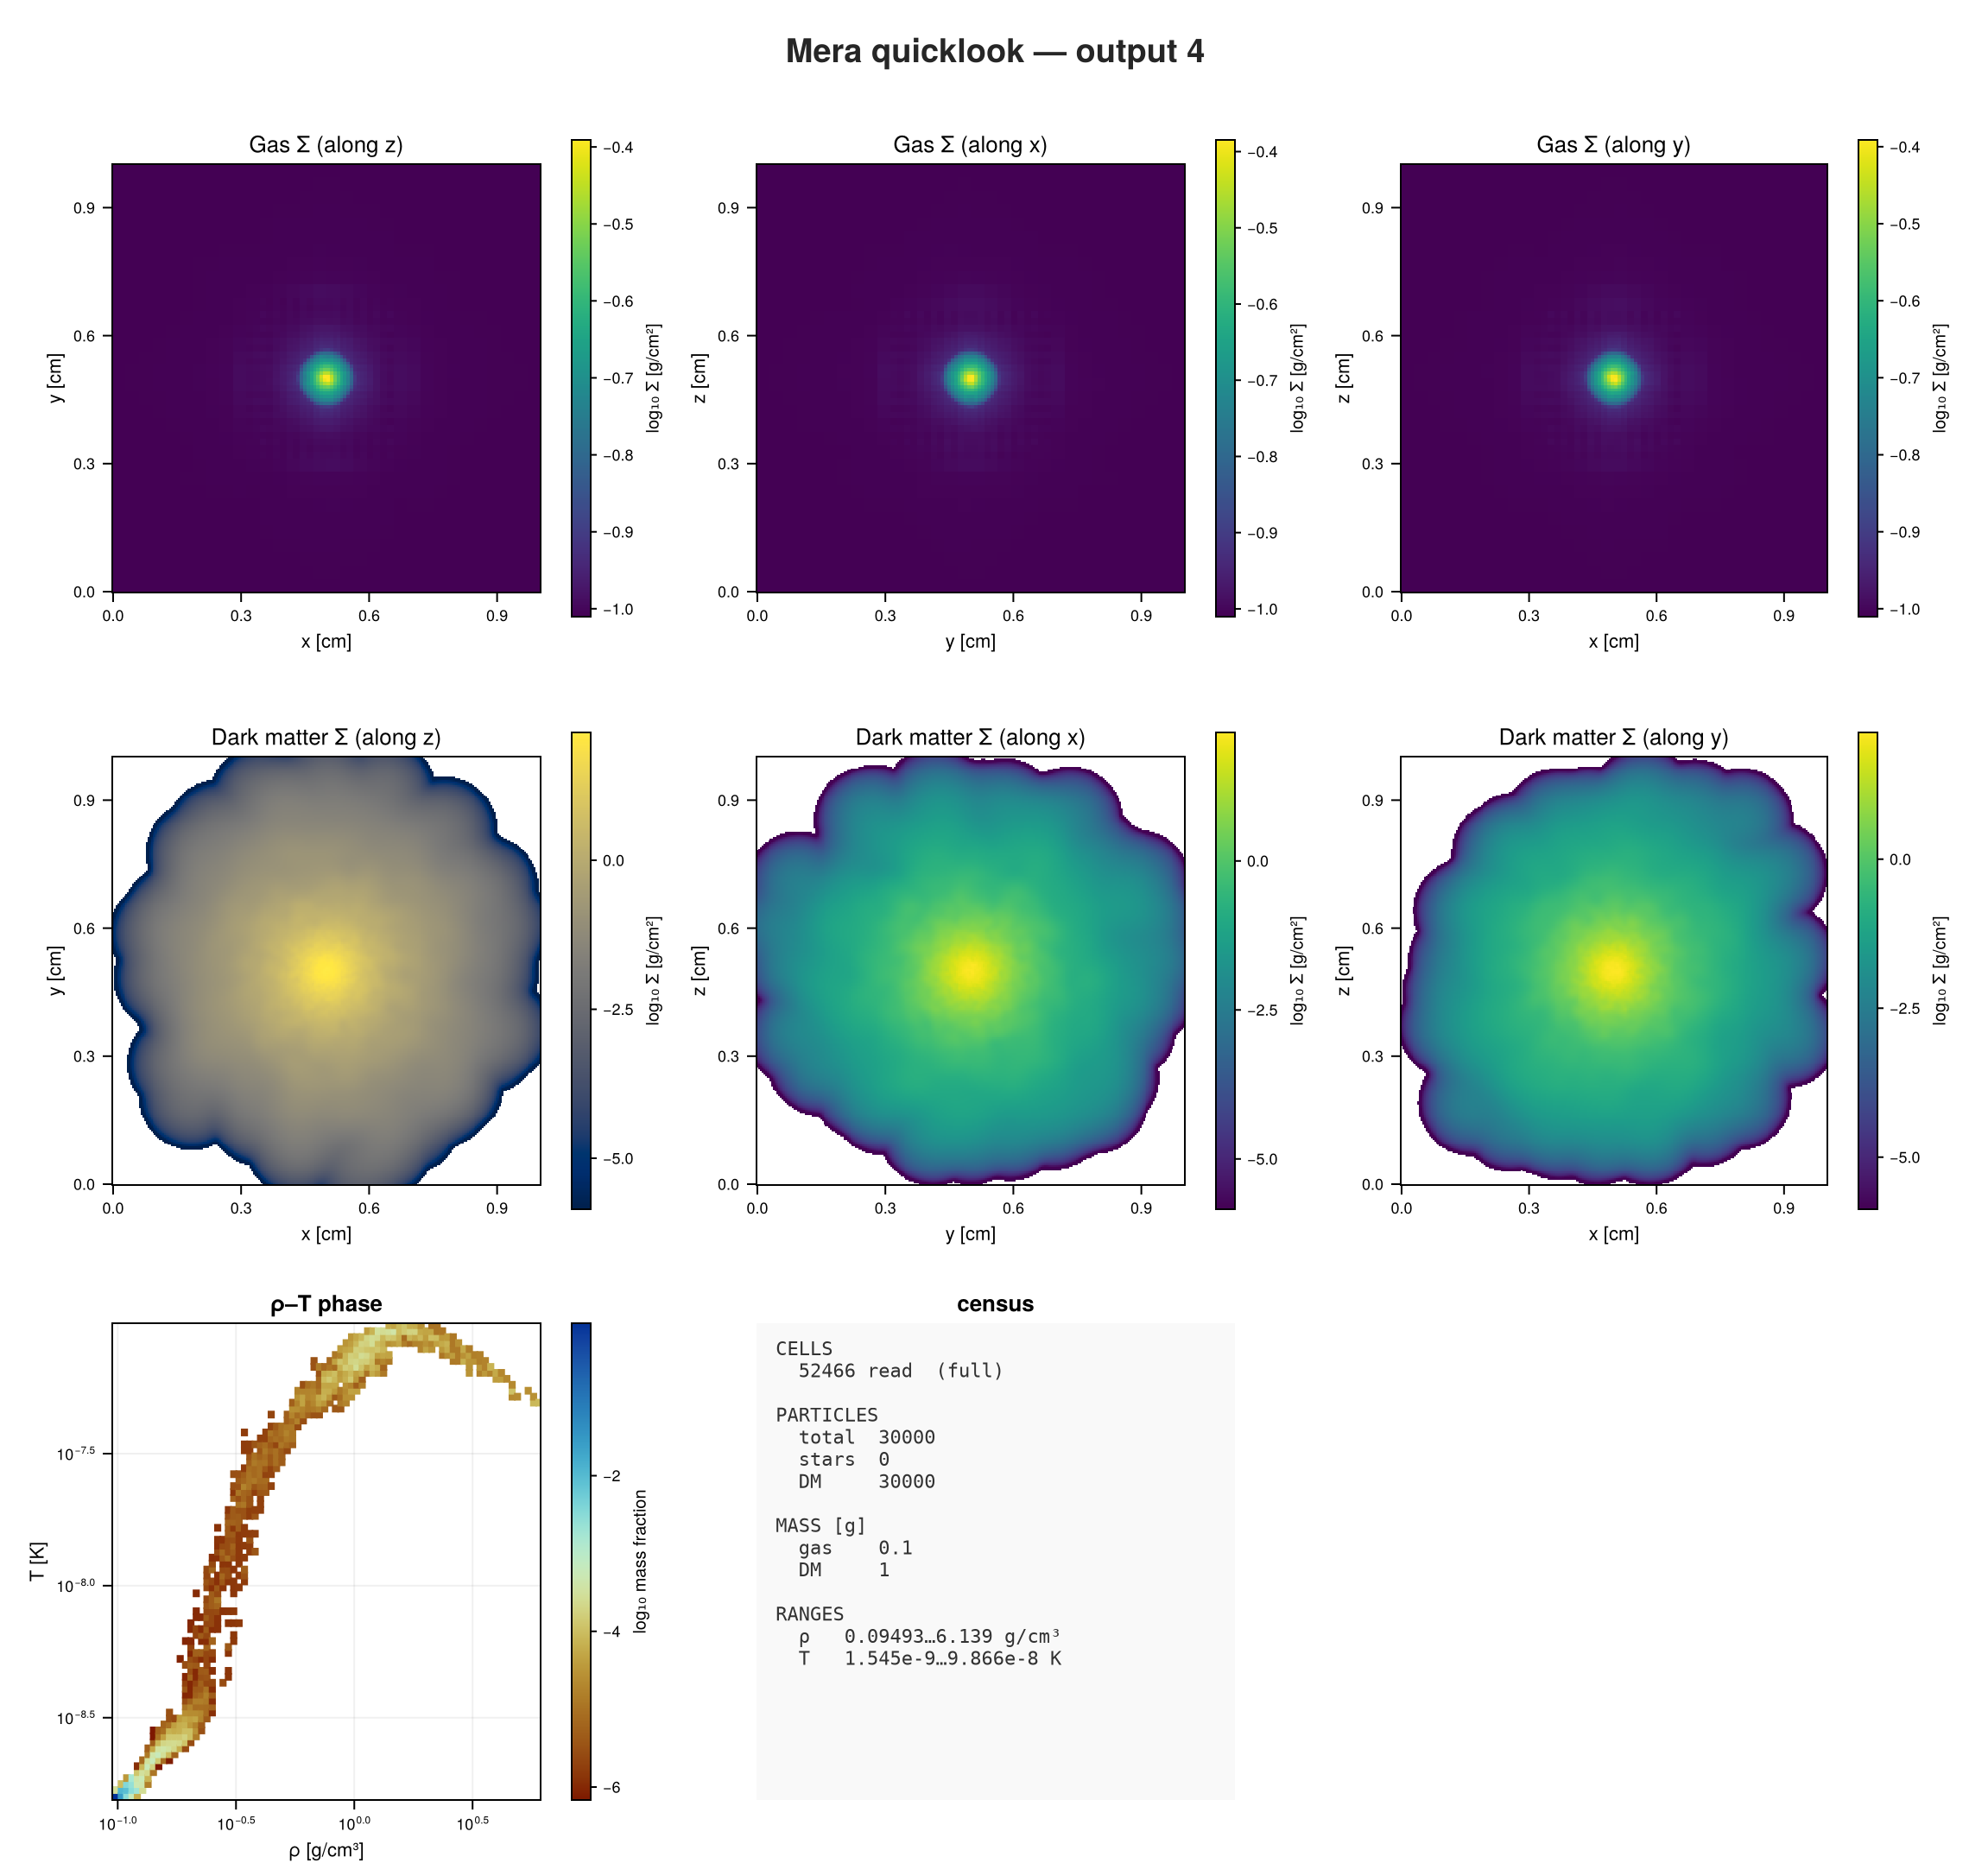

In [7]:
quicklookplot(look(4, "dm_gas3d_bisection"))

## Sinks

### `sinks3d`: one sink

A sink is an accreting point mass. RAMSES writes sinks to their own catalogue, and the dashboard
marks each one with a circle on the maps.

- **Known answer.** **Sinks:** one sink, whose mass grows between snapshots; the sink catalogue survives a Mera-file round trip; the dashboard counts it.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 38](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/38_report_tests.jl): quicklook and report; [test 82](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/82_loadall_tests.jl): loading every data type at once
- **Docs.** [Data Inspection: Sinks](01_sinks_First_Inspection.md), [Pipelines](pipelines.md), [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 2, reading gas: 2026-10-27T12:52:24.266

   8 CPU file(s), levels 5-6 of 6  (full resolution)


Processing files:   0%|                                                  |  ETA: N/A (  N/A  s/it)

Processing files: 100%|██████████████████████████████████████████████████| Time: 0:00:00 (17.57 ms/it)



✓ File processing complete! Combining results...


   projecting 3 gas map(s) [z, x, y] and the phase diagram from 262144 cells


[Mera]: quicklook output 2, reading particles: 2026-10-27T12:52:24.700



┌─ Mera quicklook ── output 2 (RAMSES) ───────────────


│ box        : 250 pc      levels 5–6  (finest 3.906 pc)
│ grid       : ndim 3 · ncpu 8 · nvarh 5 · periodic box
│ time       : 26.18 Myr
│ read       : 262144 cells  (full resolution)
│ gas mass   : 3.828e6 M⊙
│ n_H range  : 4.307 … 7.614 cm⁻³
│ T range    : 5.406 … 7.063 K
│ sinks      : 1  ·  mass 2721 M⊙
└─ 1.0 s ──────────────────────────────────
[Mera]: quicklook output 2 finished: 2026-10-27T12:52:25.259



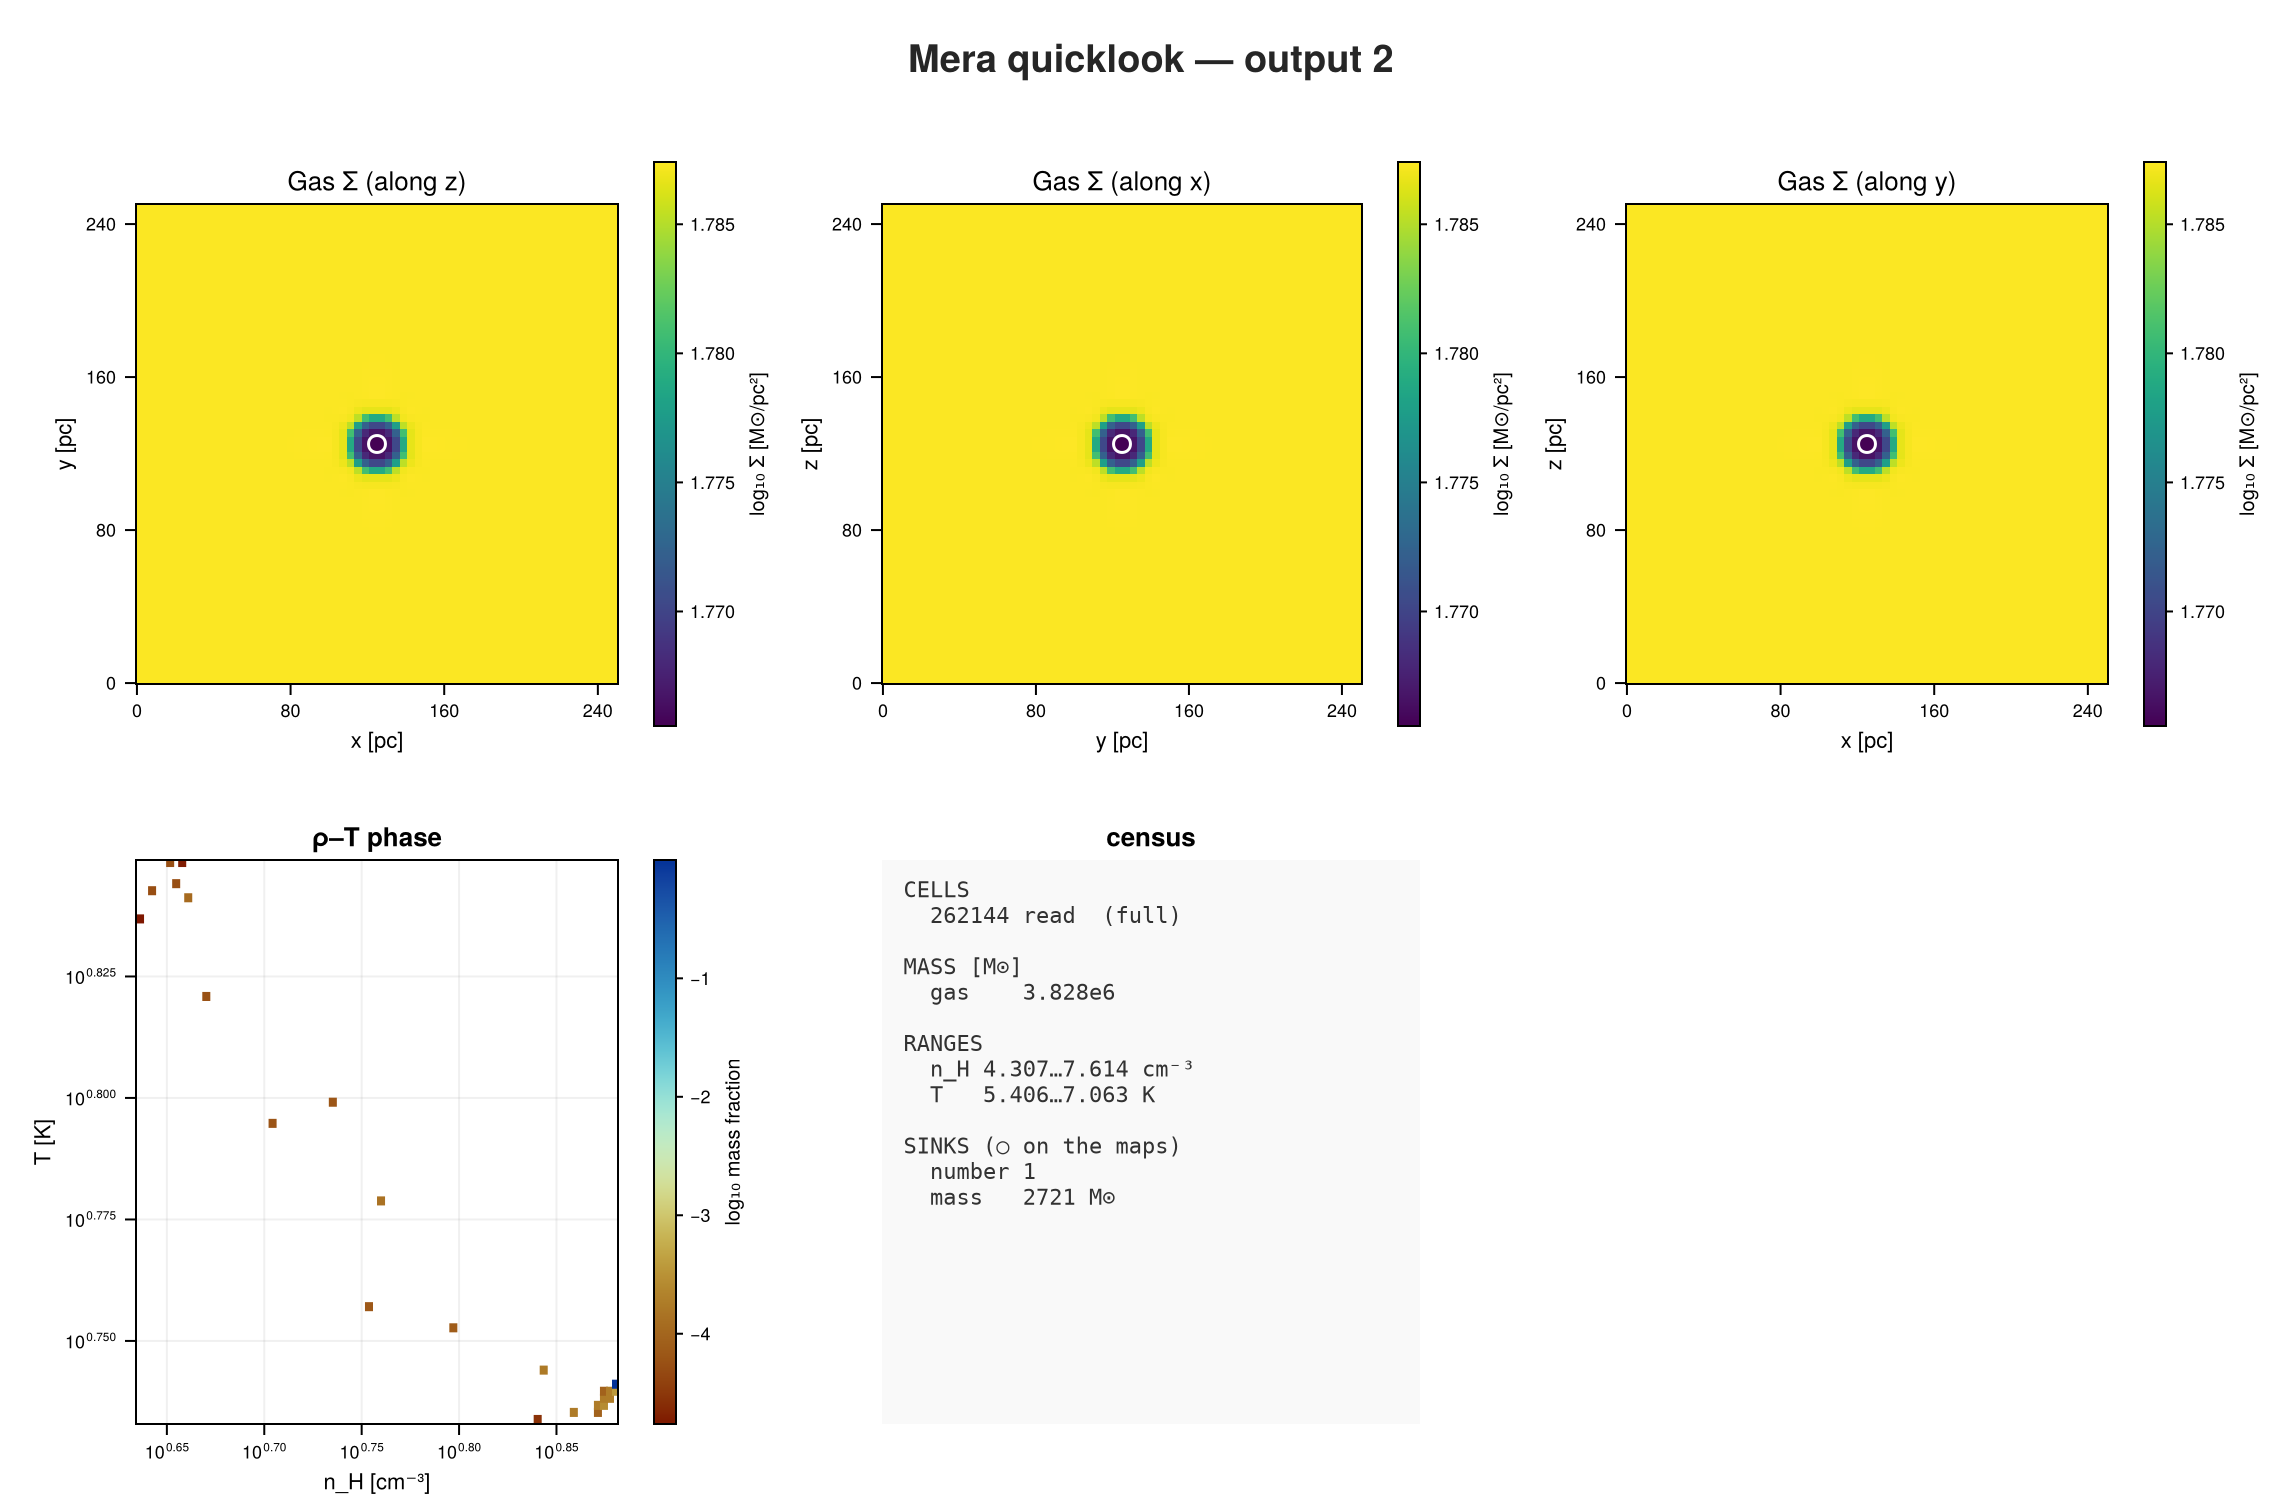

In [8]:
quicklookplot(look(2, "sinks3d"))

### `ramses_smbh_bondi`: Bondi accretion

RAMSES's own test of a black hole accreting from the surrounding gas, run unchanged. It is the
largest of the set, so `quicklook` reads it one level coarser to stay within its cell budget, and
says so. A density profile around the sink shows the gas falling in.

- **Known answer.** **Published:** the 40 numbers of RAMSES's own `sink/smbh-bondi` reference solution, 24 of them on the sink.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry
- **Docs.** this page only

[Mera]: quicklook output 15, reading gas: 2026-10-27T12:52:26.051

   8 CPU file(s), levels 6-7 of 8  (budgeted to ~2000000 cells)


Processing files:   0%|                                                  |  ETA: N/A (  N/A  s/it)

Processing files:  50%|█████████████████████████                         |  ETA: 0:00:01 ( 0.19  s/it)

Processing files: 100%|██████████████████████████████████████████████████| Time: 0:00:00 ( 0.10  s/it)



✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 2097152 cells


[Mera]: quicklook output 15, reading particles: 2026-10-27T12:52:27.760



[ Info: sfr_snapshot: using eta_sn=1.0e-10 from the run's namelist to rebuild birth masses from the current :mass. Stars older than 5.0 Myr are scaled by 1/(1-eta_sn), which RAISES the rate. Pass eta_sn=0 to switch this off, or eta_sn=<value> to set it.


┌─ Mera quicklook ── output 15 (RAMSES) ───────────────
│ box        : 1 kpc      levels 6–8  (finest 3.906 pc)
│ grid       : ndim 3 · ncpu 8 · nvarh 5 · nonperiodic box
│ time       : 51940 yr
│ read       : 2097152 cells  ⚠ coarse levels ≤ 7 of 8
│ gas mass   : 245200 M⊙  (mass-conserving)
│ n_H range  : 0.007415 … 0.1147 cm⁻³  ⚠ peaks smoothed (lower bound)
│ T range    : 1.705 … 66650 K  ⚠ peaks smoothed (lower bound)
│ sinks      : 1  ·  mass 1.005e6 M⊙
└─ 2.3 s ──────────────────────────────────
[Mera]: quicklook output 15 finished: 2026-10-27T12:52:28.318



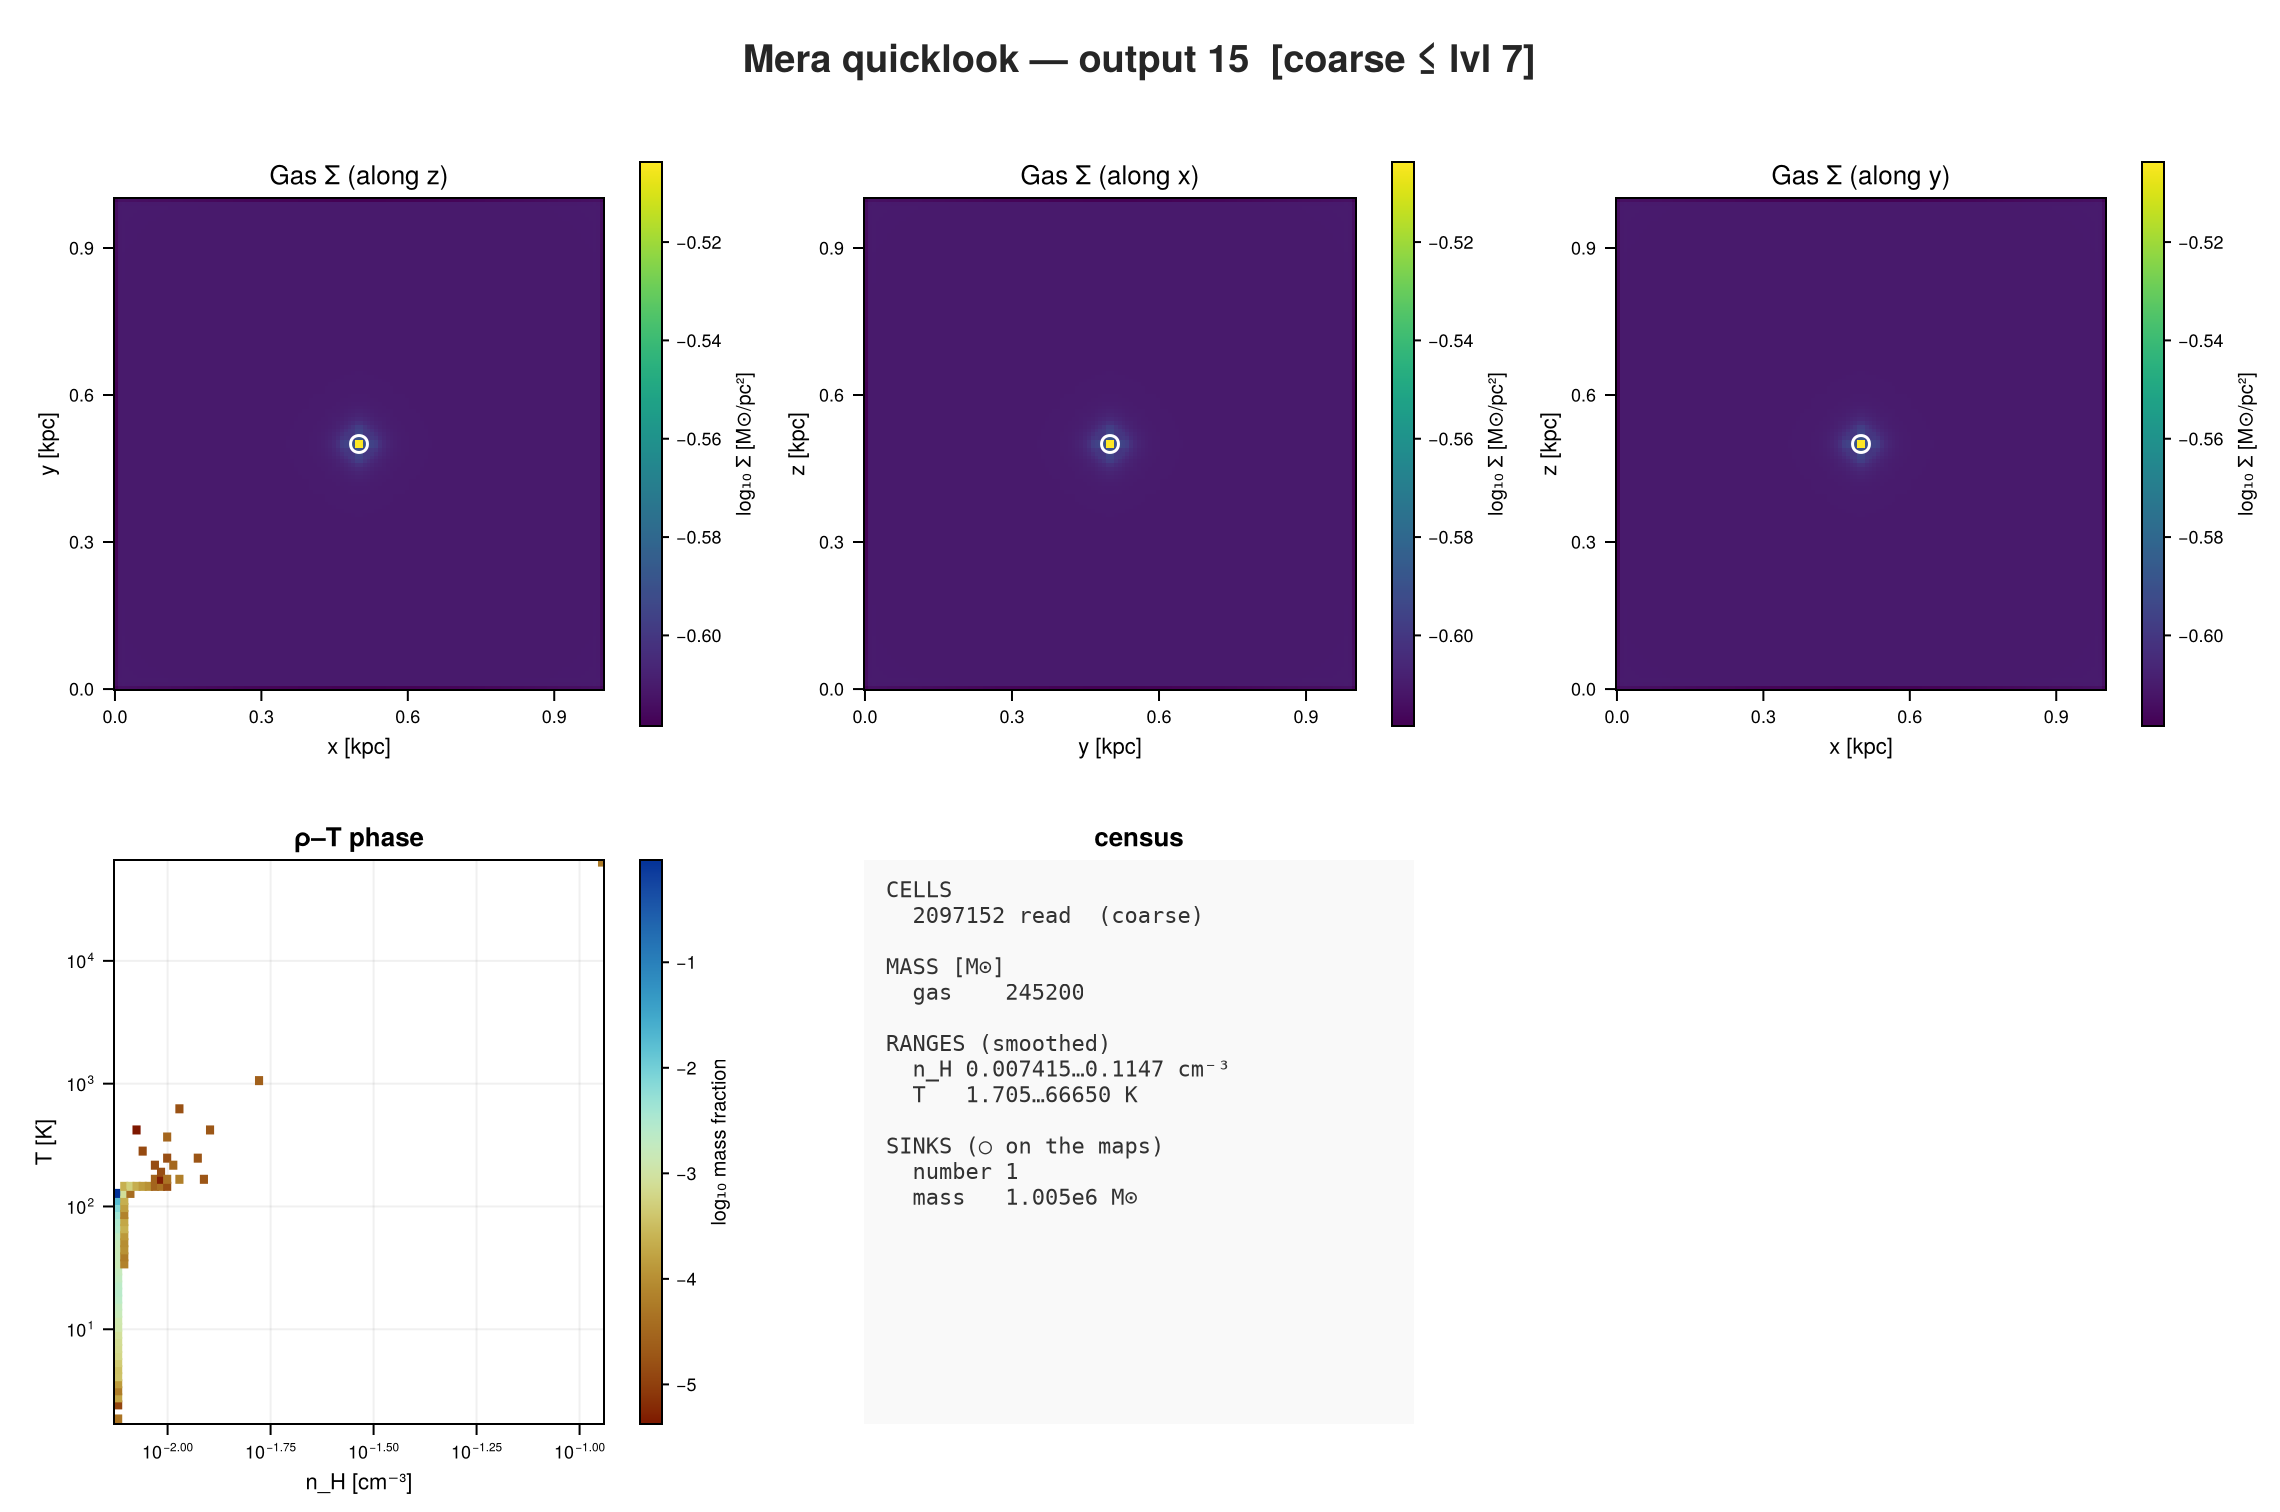

In [9]:
quicklookplot(look(15, "ramses_smbh_bondi"))

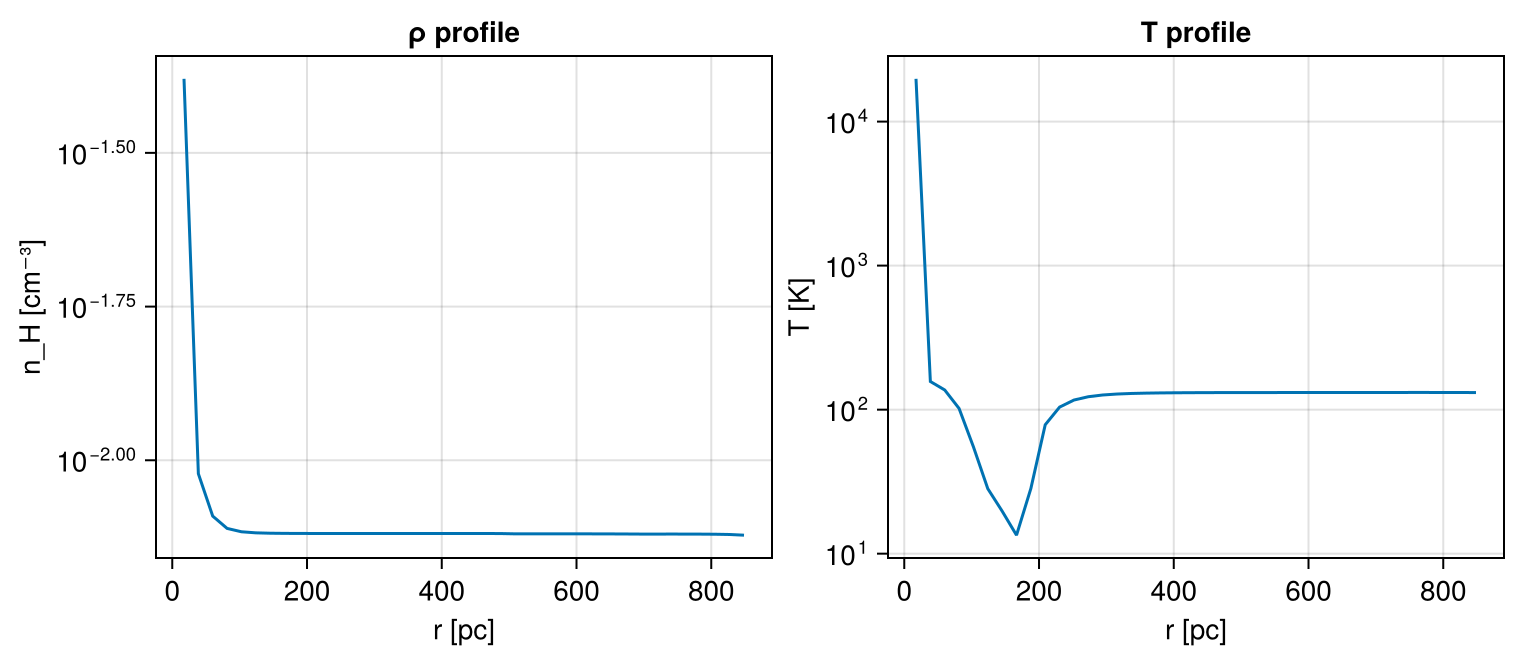

In [10]:
rep = report(15; path=sim("ramses_smbh_bondi"), output=:none, cards=[
    ProfileCard(:hydro, :r_sphere, :rho; geometry=:spherical, center=[:bc], range_unit=:pc,
                xunit=:pc, unit=:nH, nbins=40, yscale=:log),
    ProfileCard(:hydro, :r_sphere, :T; geometry=:spherical, center=[:bc], range_unit=:pc,
                xunit=:pc, unit=:K, nbins=40, yscale=:log)])
render(rep, :plot; ncols=2)

## Magnetic fields

### `mhdtube3d`: a magnetic shock tube

Two states of gas and field meet along x and launch waves in both directions. The field component
along the tube cannot change (∇·B = 0), so |B| never drops below that constant Bx. Along x the tube
projects to a uniform map; profiles along x show the waves.

- **Known answer.** **Analytic:** ∇·B = 0 forces Bx ≡ 1 everywhere, which checks Mera's average of the face-centred field. **Geometry:** the field in cylindrical and spherical components.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 38](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/38_report_tests.jl): quicklook and report
- **Docs.** [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 6, reading gas: 2026-10-27T12:52:30.896

   8 CPU file(s), levels 4-5 of 5  (full resolution)



✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 32768 cells


┌─ Mera quicklook ── output 6 (RAMSES) ───────────────


│ box        : 2 cm      levels 4–5  (finest 0.0625 cm)
│ grid       : ndim 3 · ncpu 8 · nvarh 11 · mixed box
│ time       : 0.5022 s
│ read       : 32768 cells  (full resolution)
│ gas mass   : 4.281 g
│ ρ range    : 0.1174 … 0.9924 g/cm³
│ T range    : 1.78e-8 … 3.153e-8 K
│ |B| range  : 3.546 … 6.688 G
│ plasma β   : 0.1281 … 3.947  (β<1 ⇒ B-dominated)
└─ 0.92 s ──────────────────────────────────
[Mera]: quicklook output 6 finished: 2026-10-27T12:52:31.808



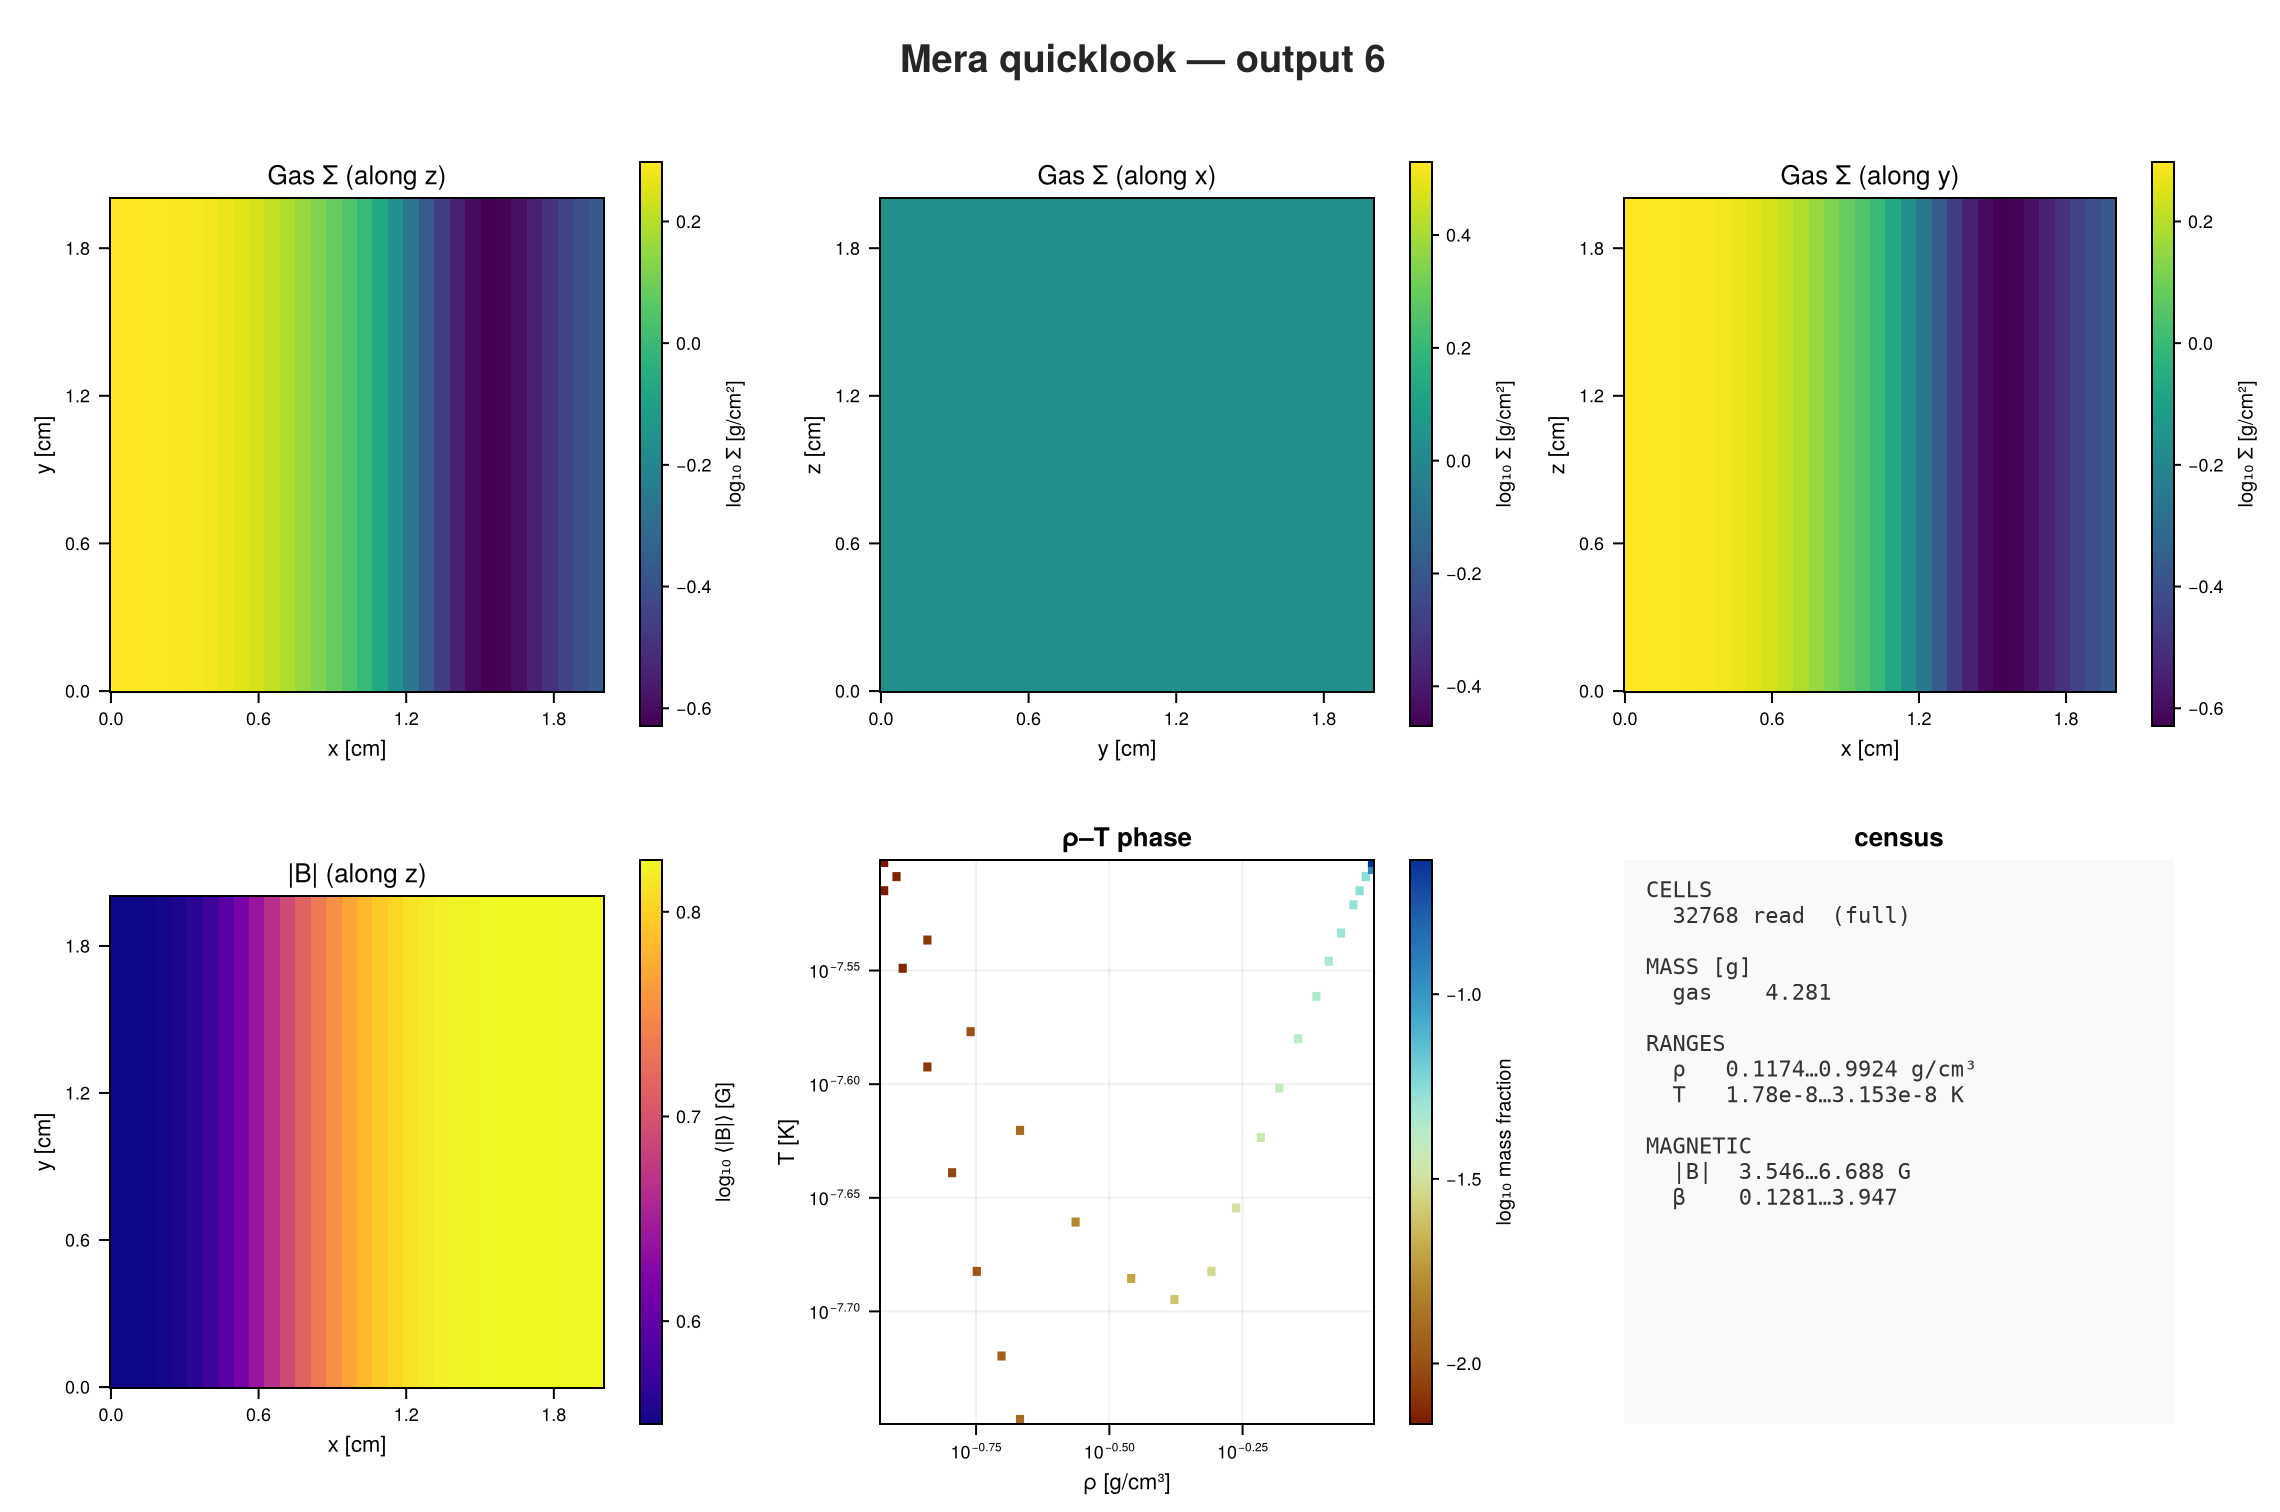

In [11]:
quicklookplot(look(6, "mhdtube3d"))

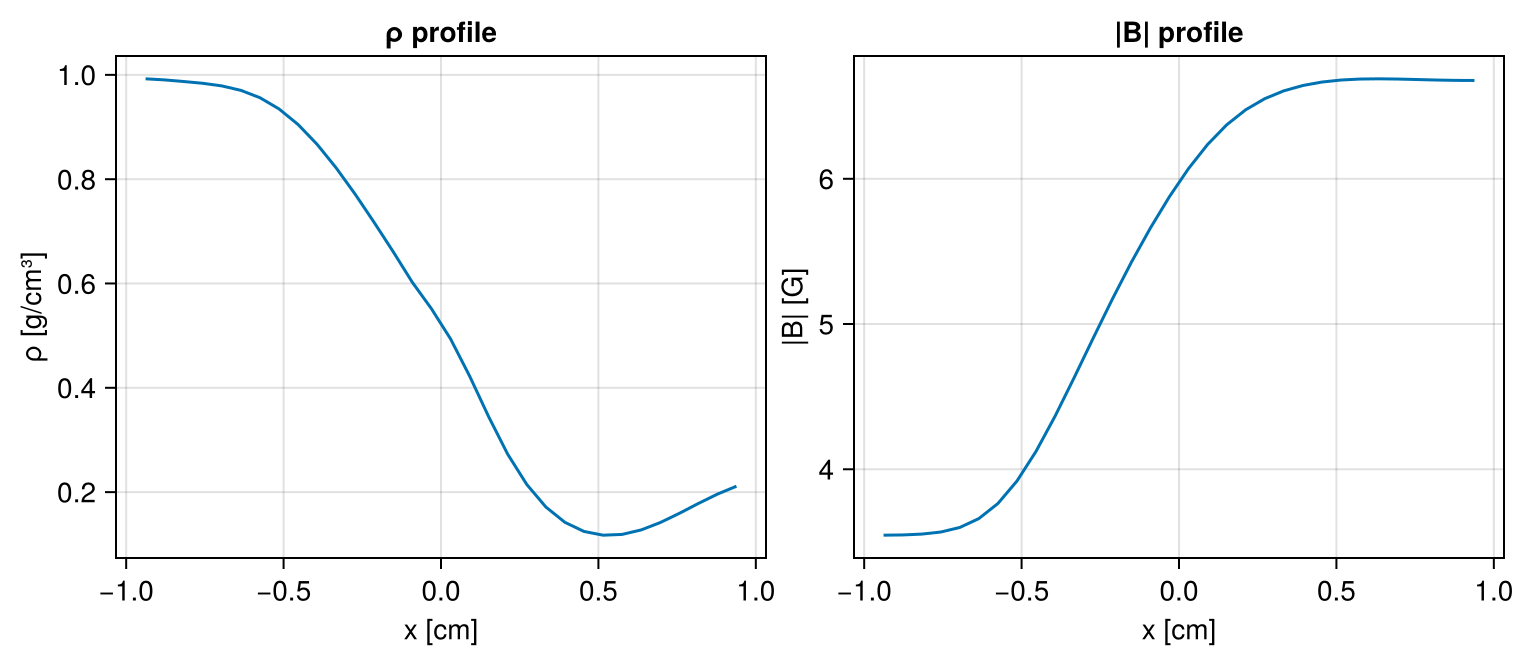

In [12]:
rep = report(6; path=sim("mhdtube3d"), output=:none, cards=[
    ProfileCard(:hydro, :x, :rho; xunit=:cm, unit=:g_cm3, nbins=32, yscale=:identity),
    ProfileCard(:hydro, :x, :bmag; xunit=:cm, unit=:Gauss, nbins=32, yscale=:identity)])
render(rep, :plot; ncols=2)

### `ramses_abc_flow`: a dynamo

RAMSES's own MHD test, run unchanged. The density stays exactly 1 g/cm³ everywhere, because the test
holds it fixed and lets a prescribed flow amplify the magnetic field. The gas maps are therefore one
colour, and the |B| panel is the one to look at.

- **Known answer.** **Published:** the 22 numbers of RAMSES's own `mhd/abc-flow` reference solution, covering all six face-centred B components.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks
- **Docs.** [Magnetic Fields](magnetic_fields.md), [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 2, reading gas: 2026-10-27T12:52:32.702

   8 CPU file(s), levels 5-5 of 5  (full resolution)



✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 32768 cells


┌─ Mera quicklook ── output 2 (RAMSES) ───────────────


│ box        : 1 cm      levels 5–5  (finest 0.03125 cm)
│ grid       : ndim 3 · ncpu 8 · nvarh 11 · periodic box
│ time       : 10 s
│ read       : 32768 cells  (full resolution)
│ gas mass   : 1 g
│ ρ range    : 1 … 1 g/cm³
│ T range    : 1.044e-8 … 1.059e-8 K
│ |B| range  : 0.005458 … 4.967 G
│ plasma β   : 0.6808 … 562500  (β<1 ⇒ B-dominated)
└─ 0.74 s ──────────────────────────────────
[Mera]: quicklook output 2 finished: 2026-10-27T12:52:33.436



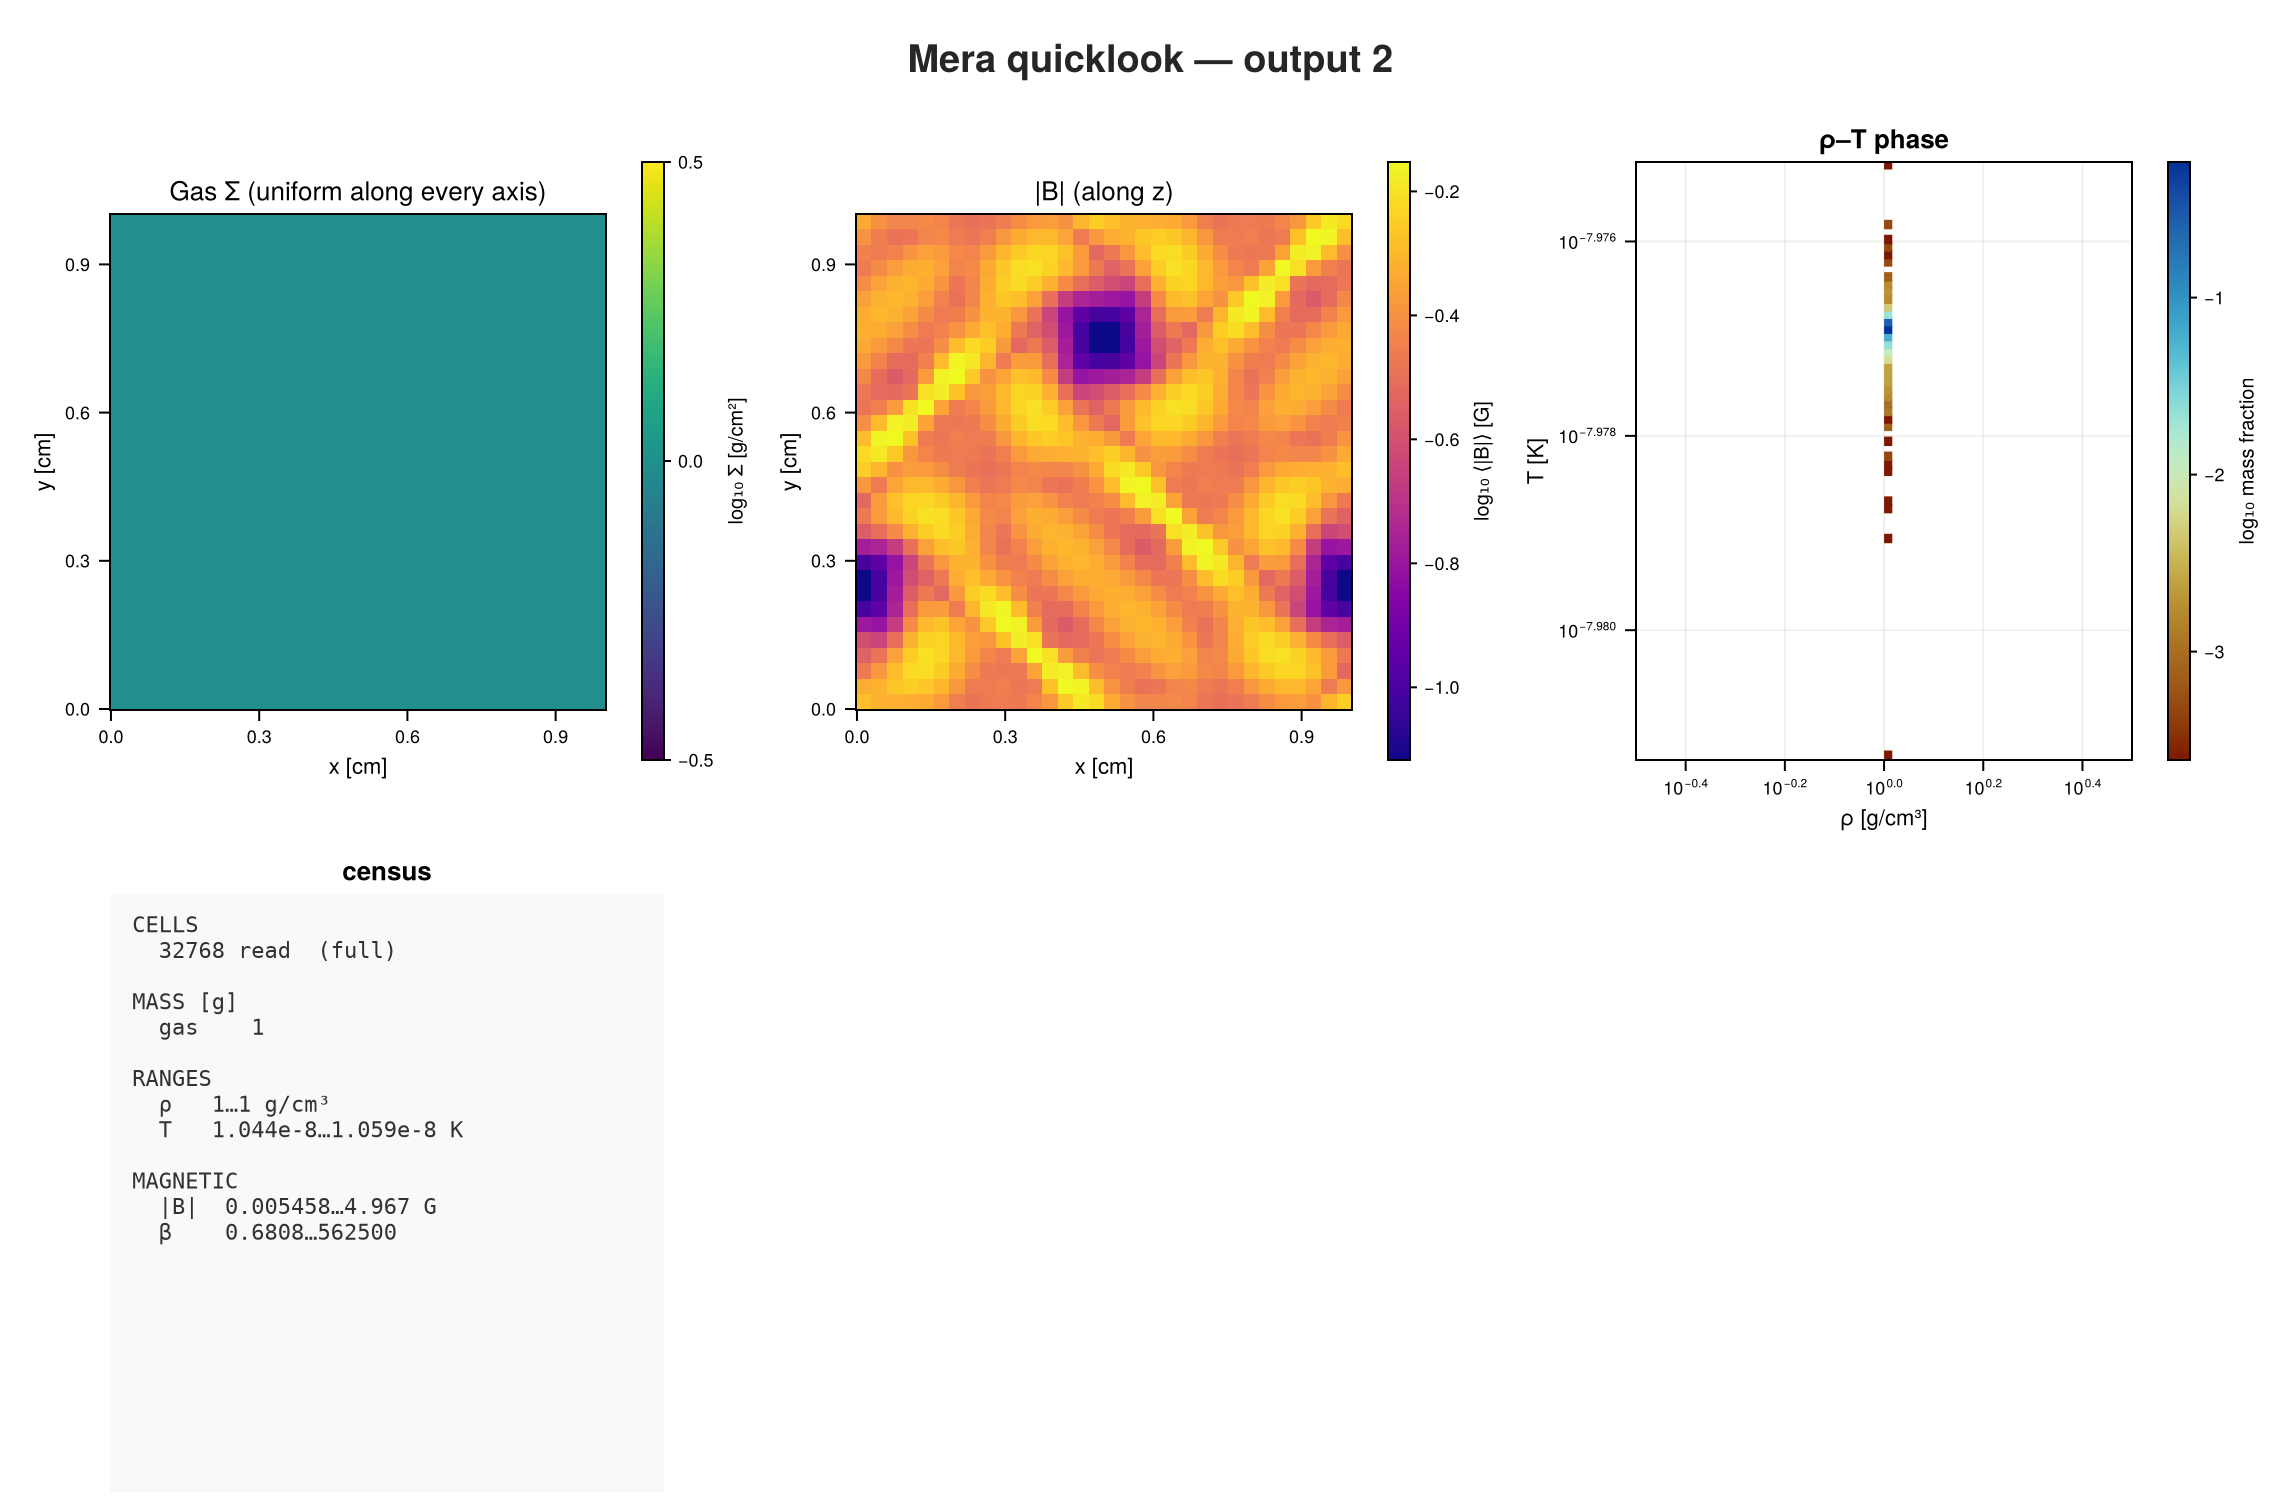

In [13]:
quicklookplot(look(2, "ramses_abc_flow"))

## Radiative transfer

### `stromgren3d`: an ionised sphere

A source in the box corner ionises uniform hydrogen gas (n_H = 10⁻³ cm⁻³, set in the run). The
ionised region grows towards the Strömgren radius, and its front follows
r(t) = r_S (1 − e^(−t/t_rec))^(1/3). The gas density does not change, so the gas maps are uniform;
the ionised-fraction map shows the sphere.

On an RT run Mera uses the run's own composition: the hydrogen fraction from its RT header
(here X = 1, pure hydrogen) and the mean molecular weight of each cell from its ionisation. The
temperature is therefore physical in both the neutral and the ionised gas.

- **Known answer.** **Analytic:** the ionisation front follows r(t) = r_S (1 − e^(−t/t_rec))^(1/3). **Composition:** n_H and the temperature use X = 1 and μ from the run.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 38](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/38_report_tests.jl): quicklook and report
- **Docs.** [Radiative Transfer](10_multi_RadiativeTransfer.md), [Pipelines](pipelines.md), [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 7, reading gas: 2026-10-27T12:52:33.812

   8 CPU file(s), levels 5-5 of 5  (full resolution)

✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 32768 cells


┌─ Mera quicklook ── output 7 (RAMSES) ───────────────


│ box        : 15 kpc      levels 5–5  (finest 468.8 pc)
│ grid       : ndim 3 · ncpu 8 · nvarh 8 · nonperiodic box
│ time       : 500 Myr
│ read       : 32768 cells  (full resolution)
│ gas mass   : 8.275e7 M⊙
│ n_H range  : 0.001 … 0.001 cm⁻³
│ T range    : 116.8 … 21600 K  (μ from the ionisation)
│ ionised    : 3.931 % of the gas mass  (xHII 4.578e-5 … 0.9996)
└─ 0.93 s ──────────────────────────────────
[Mera]: quicklook output 7 finished: 2026-10-27T12:52:34.707



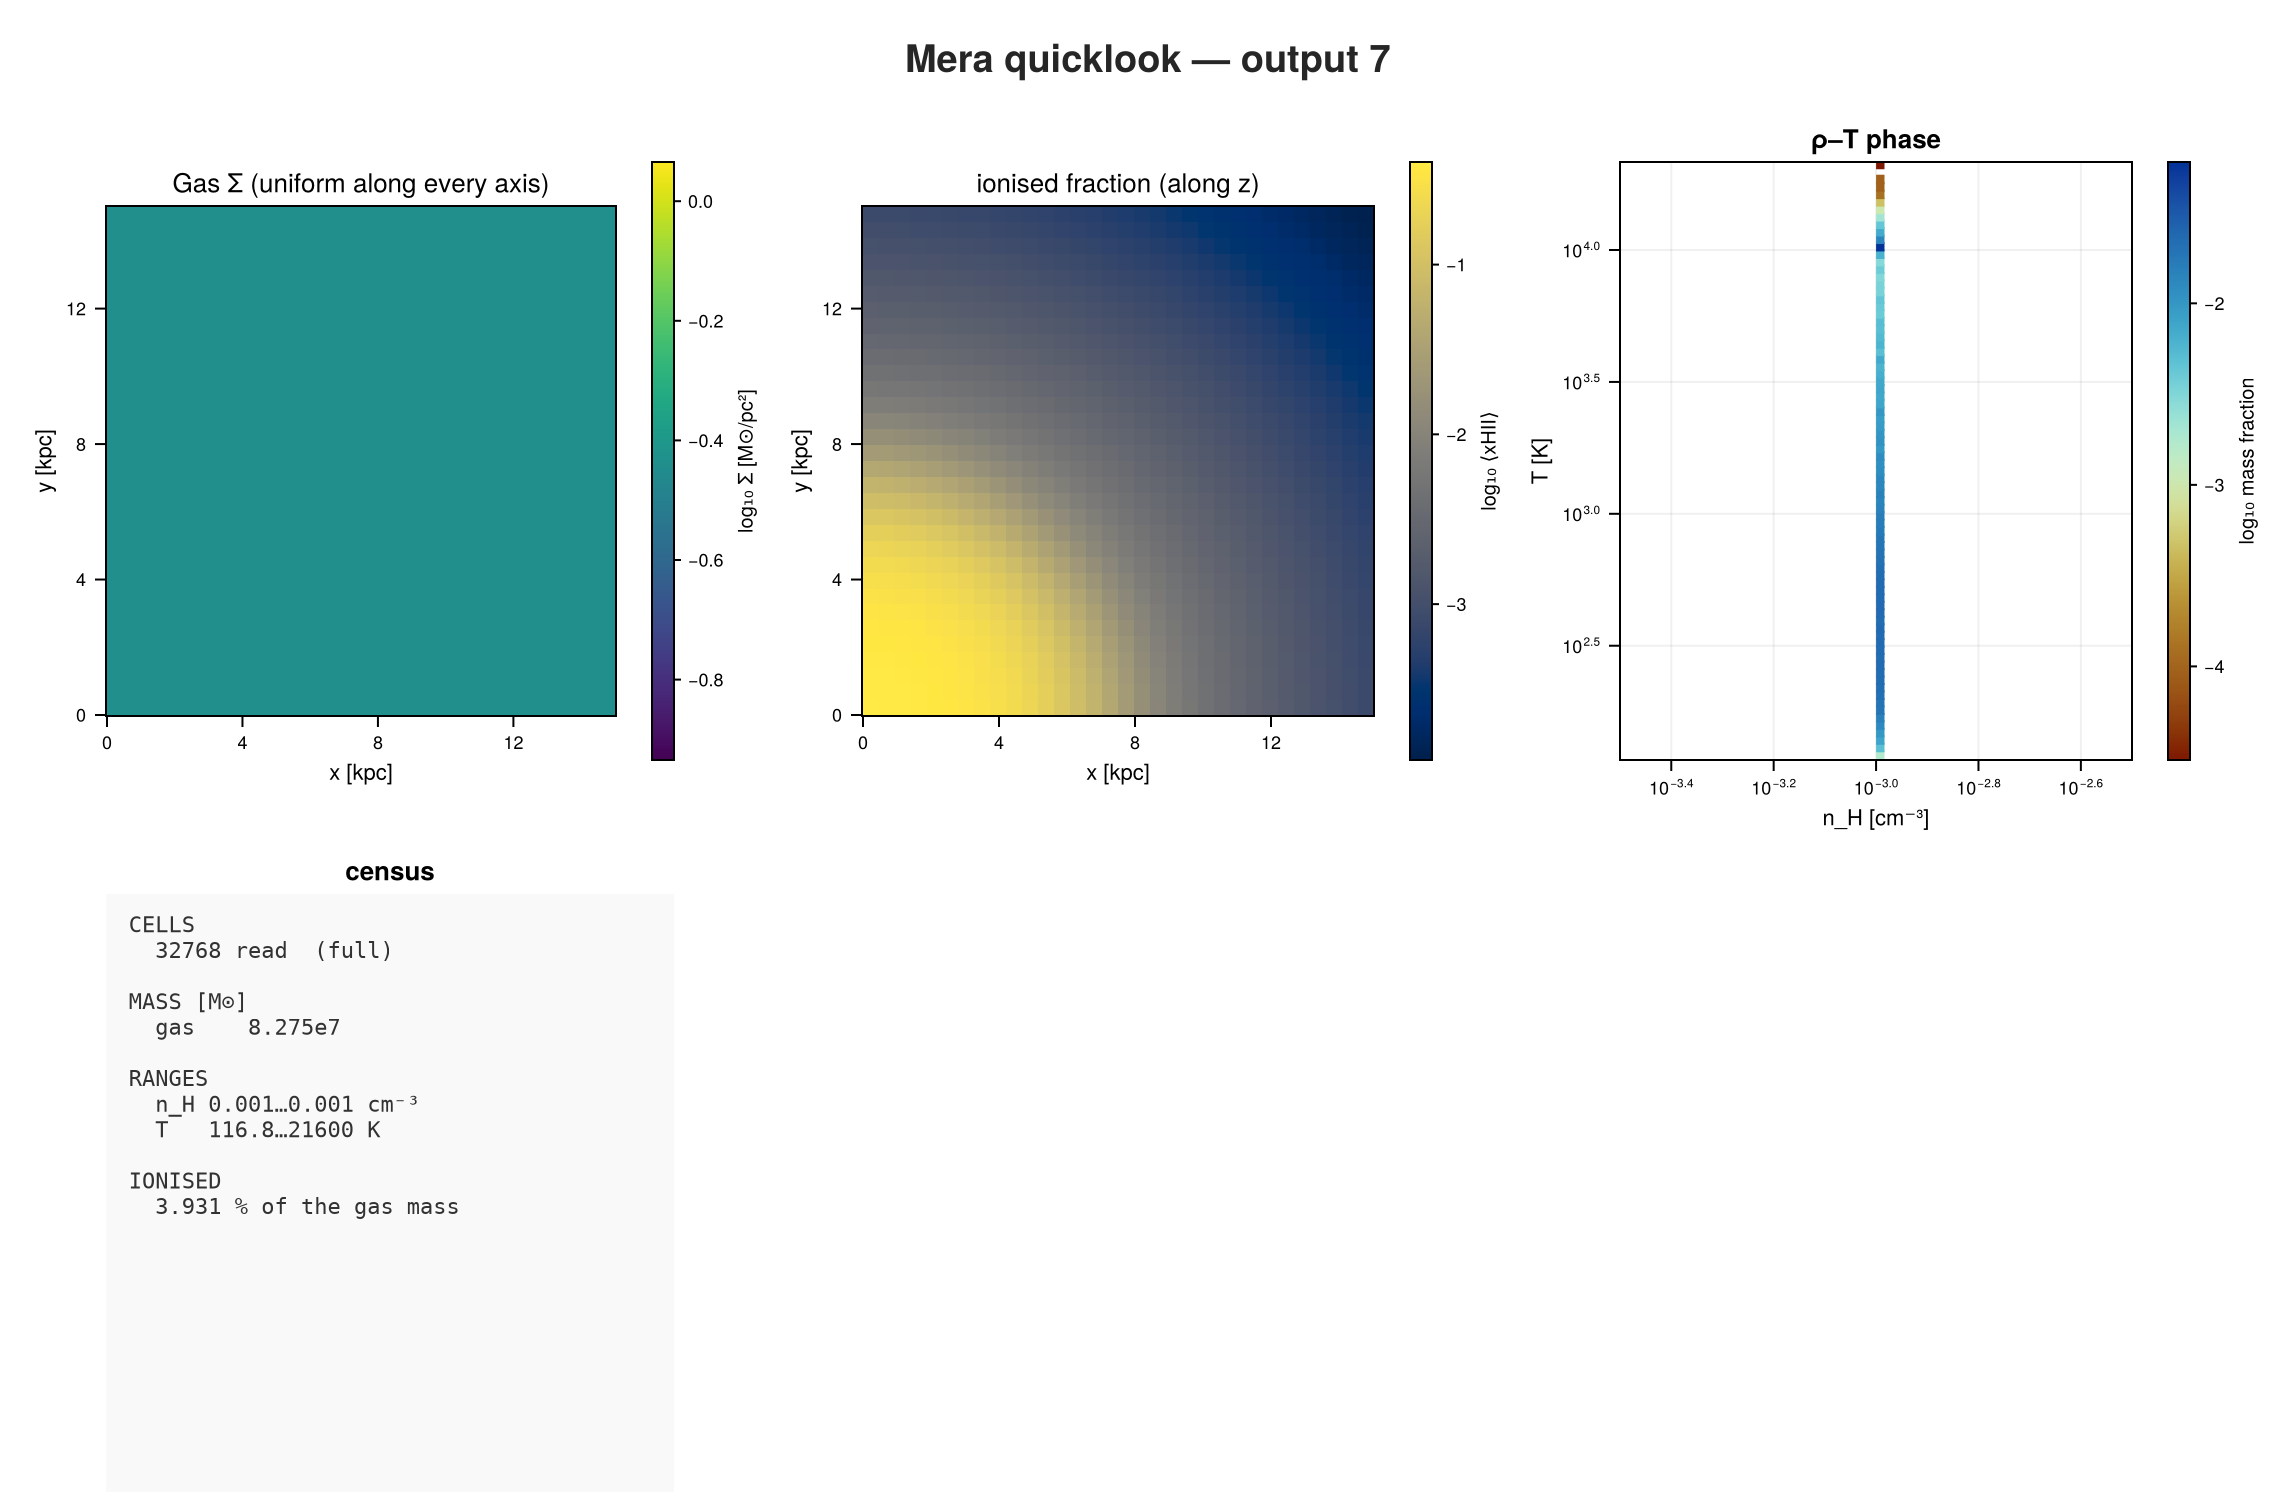

In [14]:
quicklookplot(look(7, "stromgren3d"))

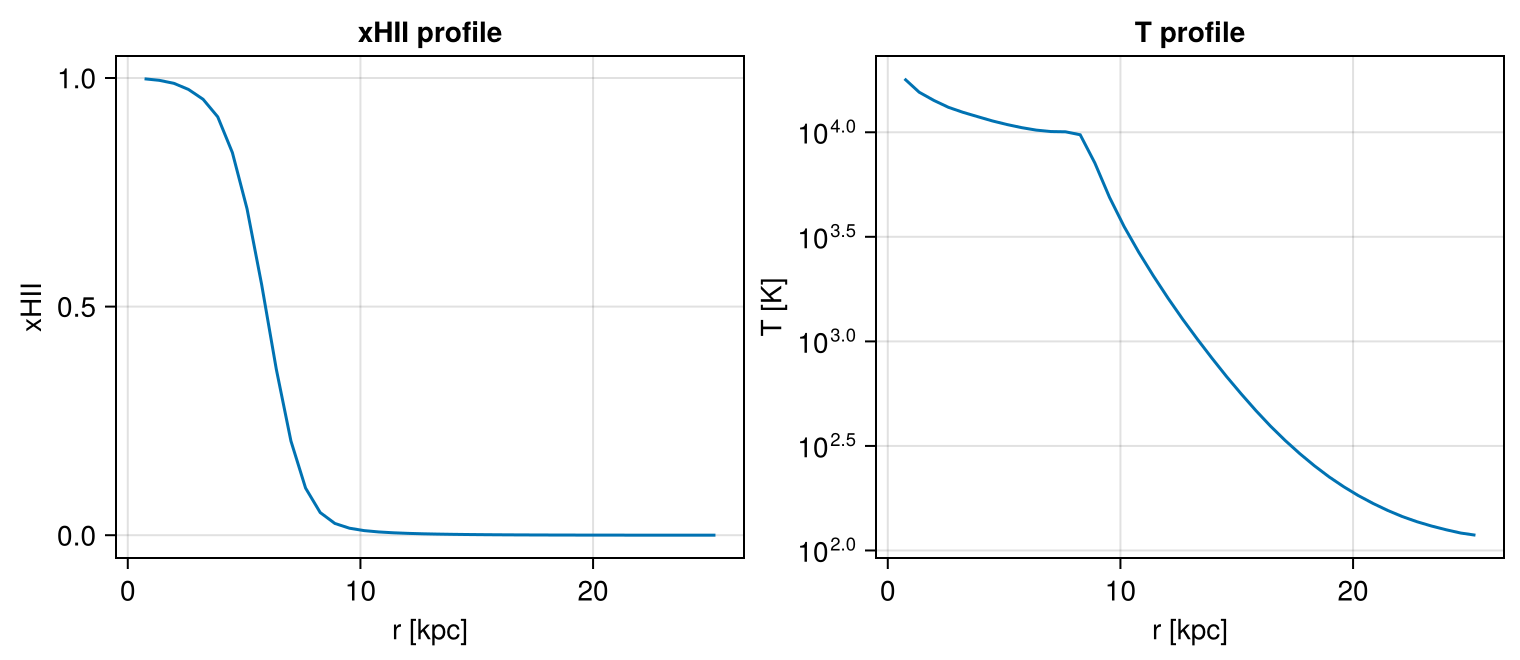

In [15]:
rep = report(7; path=sim("stromgren3d"), output=:none, cards=[
    ProfileCard(:hydro, :r_sphere, :xHII; geometry=:spherical, center=[0.0, 0.0, 0.0],
                range_unit=:kpc, xunit=:kpc, nbins=40, yscale=:identity),
    ProfileCard(:hydro, :r_sphere, :T; geometry=:spherical, center=[0.0, 0.0, 0.0],
                range_unit=:kpc, xunit=:kpc, unit=:K, nbins=40, yscale=:log)])
render(rep, :plot; ncols=2)

### `ramses_rt_dirac`: radiation with MHD

RAMSES's own RT test with the MHD solver, run unchanged: three sources in a magnetised medium. The
photon density of the first group shows the radiation spreading from the sources.

- **Known answer.** **Published:** the 25 numbers of RAMSES's own `rt/rt-dirac` reference solution, including the ionisation scalars. **RT with MHD:** the ionised fractions are read from the right columns.
- **Test suite.** [test 76](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/76_public_fixtures_tests.jl): known answers: analytic laws, RAMSES's published reference values, periodic geometry; [test 32](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/32_rt_tests.jl): radiative-transfer quantities; [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 82](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/82_loadall_tests.jl): loading every data type at once
- **Docs.** [Data Inspection: RT](01_rt_First_Inspection.md), [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 2, reading gas: 2026-10-27T12:52:35.123

   8 CPU file(s), levels 3-6 of 6  (full resolution)



✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 25040 cells


┌─ Mera quicklook ── output 2 (RAMSES) ───────────────


│ box        : 5 pc      levels 3–6  (finest 0.07812 pc)
│ grid       : ndim 3 · ncpu 8 · nvarh 14 · periodic box
│ time       : 30010 yr
│ read       : 25040 cells  (full resolution)
│ gas mass   : 4033 M⊙
│ n_H range  : 183.7 … 2345 cm⁻³
│ T range    : 15.08 … 9709 K  (μ from the ionisation)
│ ionised    : 0.2054 % of the gas mass  (xHII 1e-20 … 1)
│ |B| range  : 8.273 … 61.4 μG
│ plasma β   : 0.06187 … 300.9  (β<1 ⇒ B-dominated)
└─ 0.82 s ──────────────────────────────────
[Mera]: quicklook output 2 finished: 2026-10-27T12:52:35.932



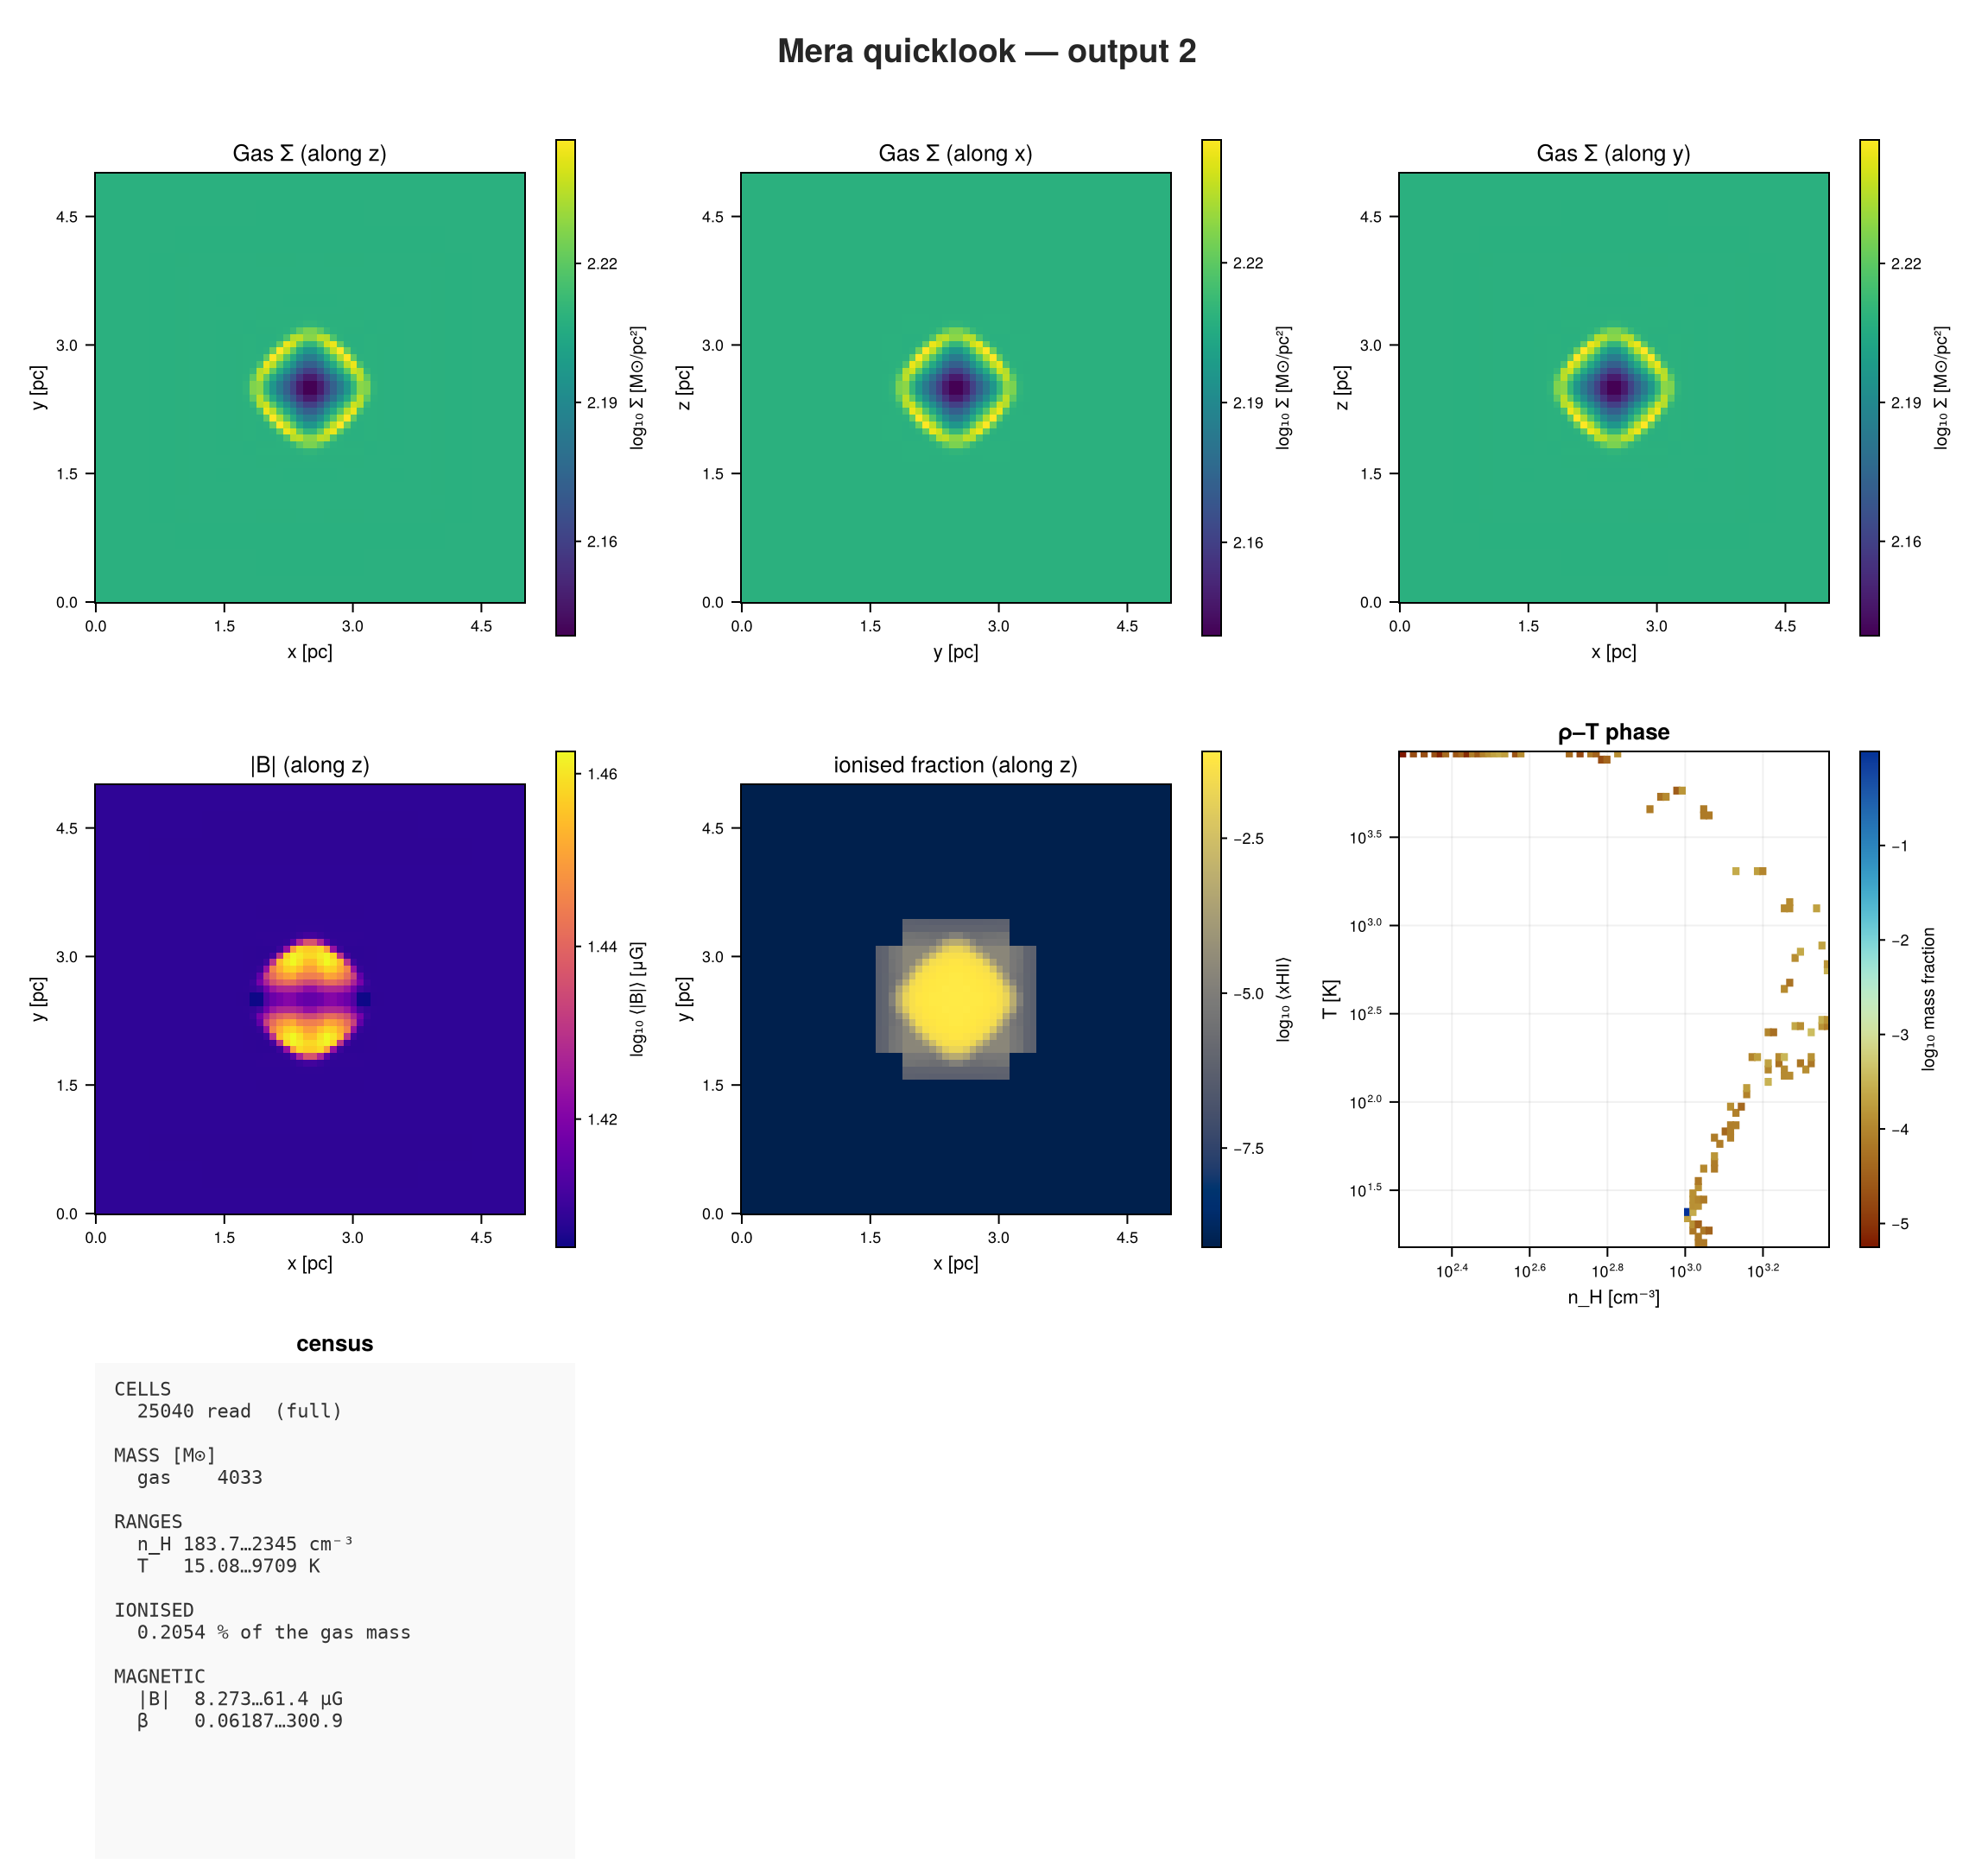

In [16]:
quicklookplot(look(2, "ramses_rt_dirac"))

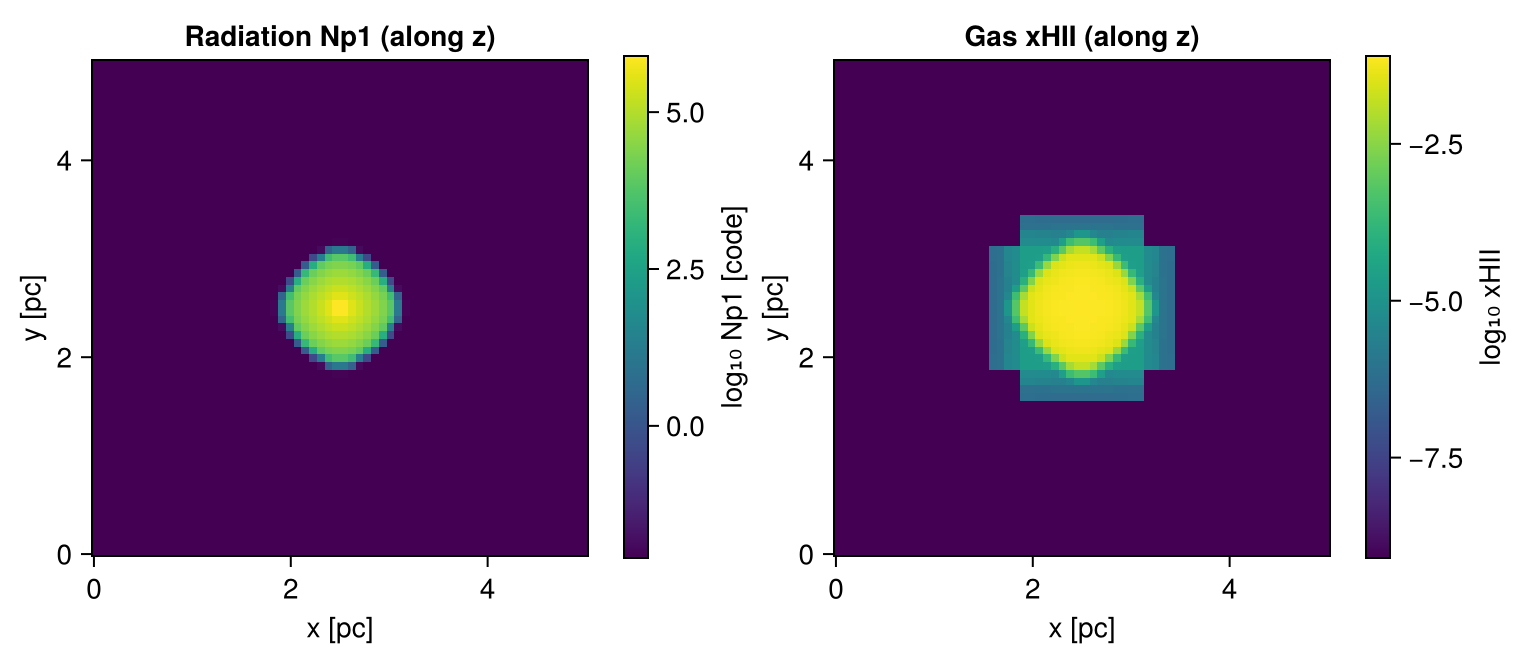

In [17]:
rep = report(2; path=sim("ramses_rt_dirac"), output=:none, cards=[
    ProjectionCard(:rt, :Np1; res=128),
    ProjectionCard(:hydro, :xHII; res=128)])
render(rep, :plot; ncols=2)

## Cosmology

### `cosmo3d`: a small cosmological box

Gas and dark matter from RAMSES's cosmological initial conditions, here at z ≈ 9. The box is
125 kpc across now and 1.25 Mpc comoving. Filaments and the first haloes show in the gas and in the
dark matter. The dark-matter particles still sit close to their starting grid; `quicklook` spreads
each one over its 32 nearest neighbours, so the maps show the matter rather than that grid.

The run has no cooling and no heating, so the gas in the emptiest regions cools far below a
kelvin as the box expands. That cold tail in the phase diagram is real.

- **Known answer.** **RAMSES files, cosmological run:** every rank's file rebuilt exactly, with 32 768 dark-matter particles and Poisson's equation in physical units.
- **Test suite.** [test 86](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/86_ramses_writer_tests.jl): writing RAMSES files: every rank's file rebuilt exactly, repartitioned to other numbers of MPI ranks; [test 38](https://github.com/ManuelBehrendt/Mera.jl/blob/master/test/38_report_tests.jl): quicklook and report
- **Docs.** [RAMSES restart, any CPUs](07_2_multi_RAMSES_Restart.md)

[Mera]: quicklook output 3, reading gas: 2026-10-27T12:52:40.694

   8 CPU file(s), levels 5-8 of 8  (full resolution)



✓ File processing complete! Combining results...
   projecting 3 gas map(s) [z, x, y] and the phase diagram from 74740 cells


[Mera]: quicklook output 3, reading particles: 2026-10-27T12:52:40.905



┌─ Mera quicklook ── output 3 (RAMSES) ───────────────
│ box        : 125.5 kpc (1.25 Mpc comoving)      levels 5–8  (finest 490.1 pc)
│ grid       : ndim 3 · ncpu 8 · nvarh 5 · periodic box
│ time       : 548 Myr   z = 8.963
│ particles  : 32768 total  —  stars 0 · DM 32768
│ read       : 74740 cells  (full resolution)
│ gas mass   : 1.099e10 M⊙
│ n_H range  : 2.605e-5 … 0.1162 cm⁻³
│ T range    : 6.834e-6 … 122200 K
│ part. mass : DM 6.656e10 M⊙
└─ 0.77 s ──────────────────────────────────
[Mera]: quicklook output 3 finished: 2026-10-27T12:52:41.461



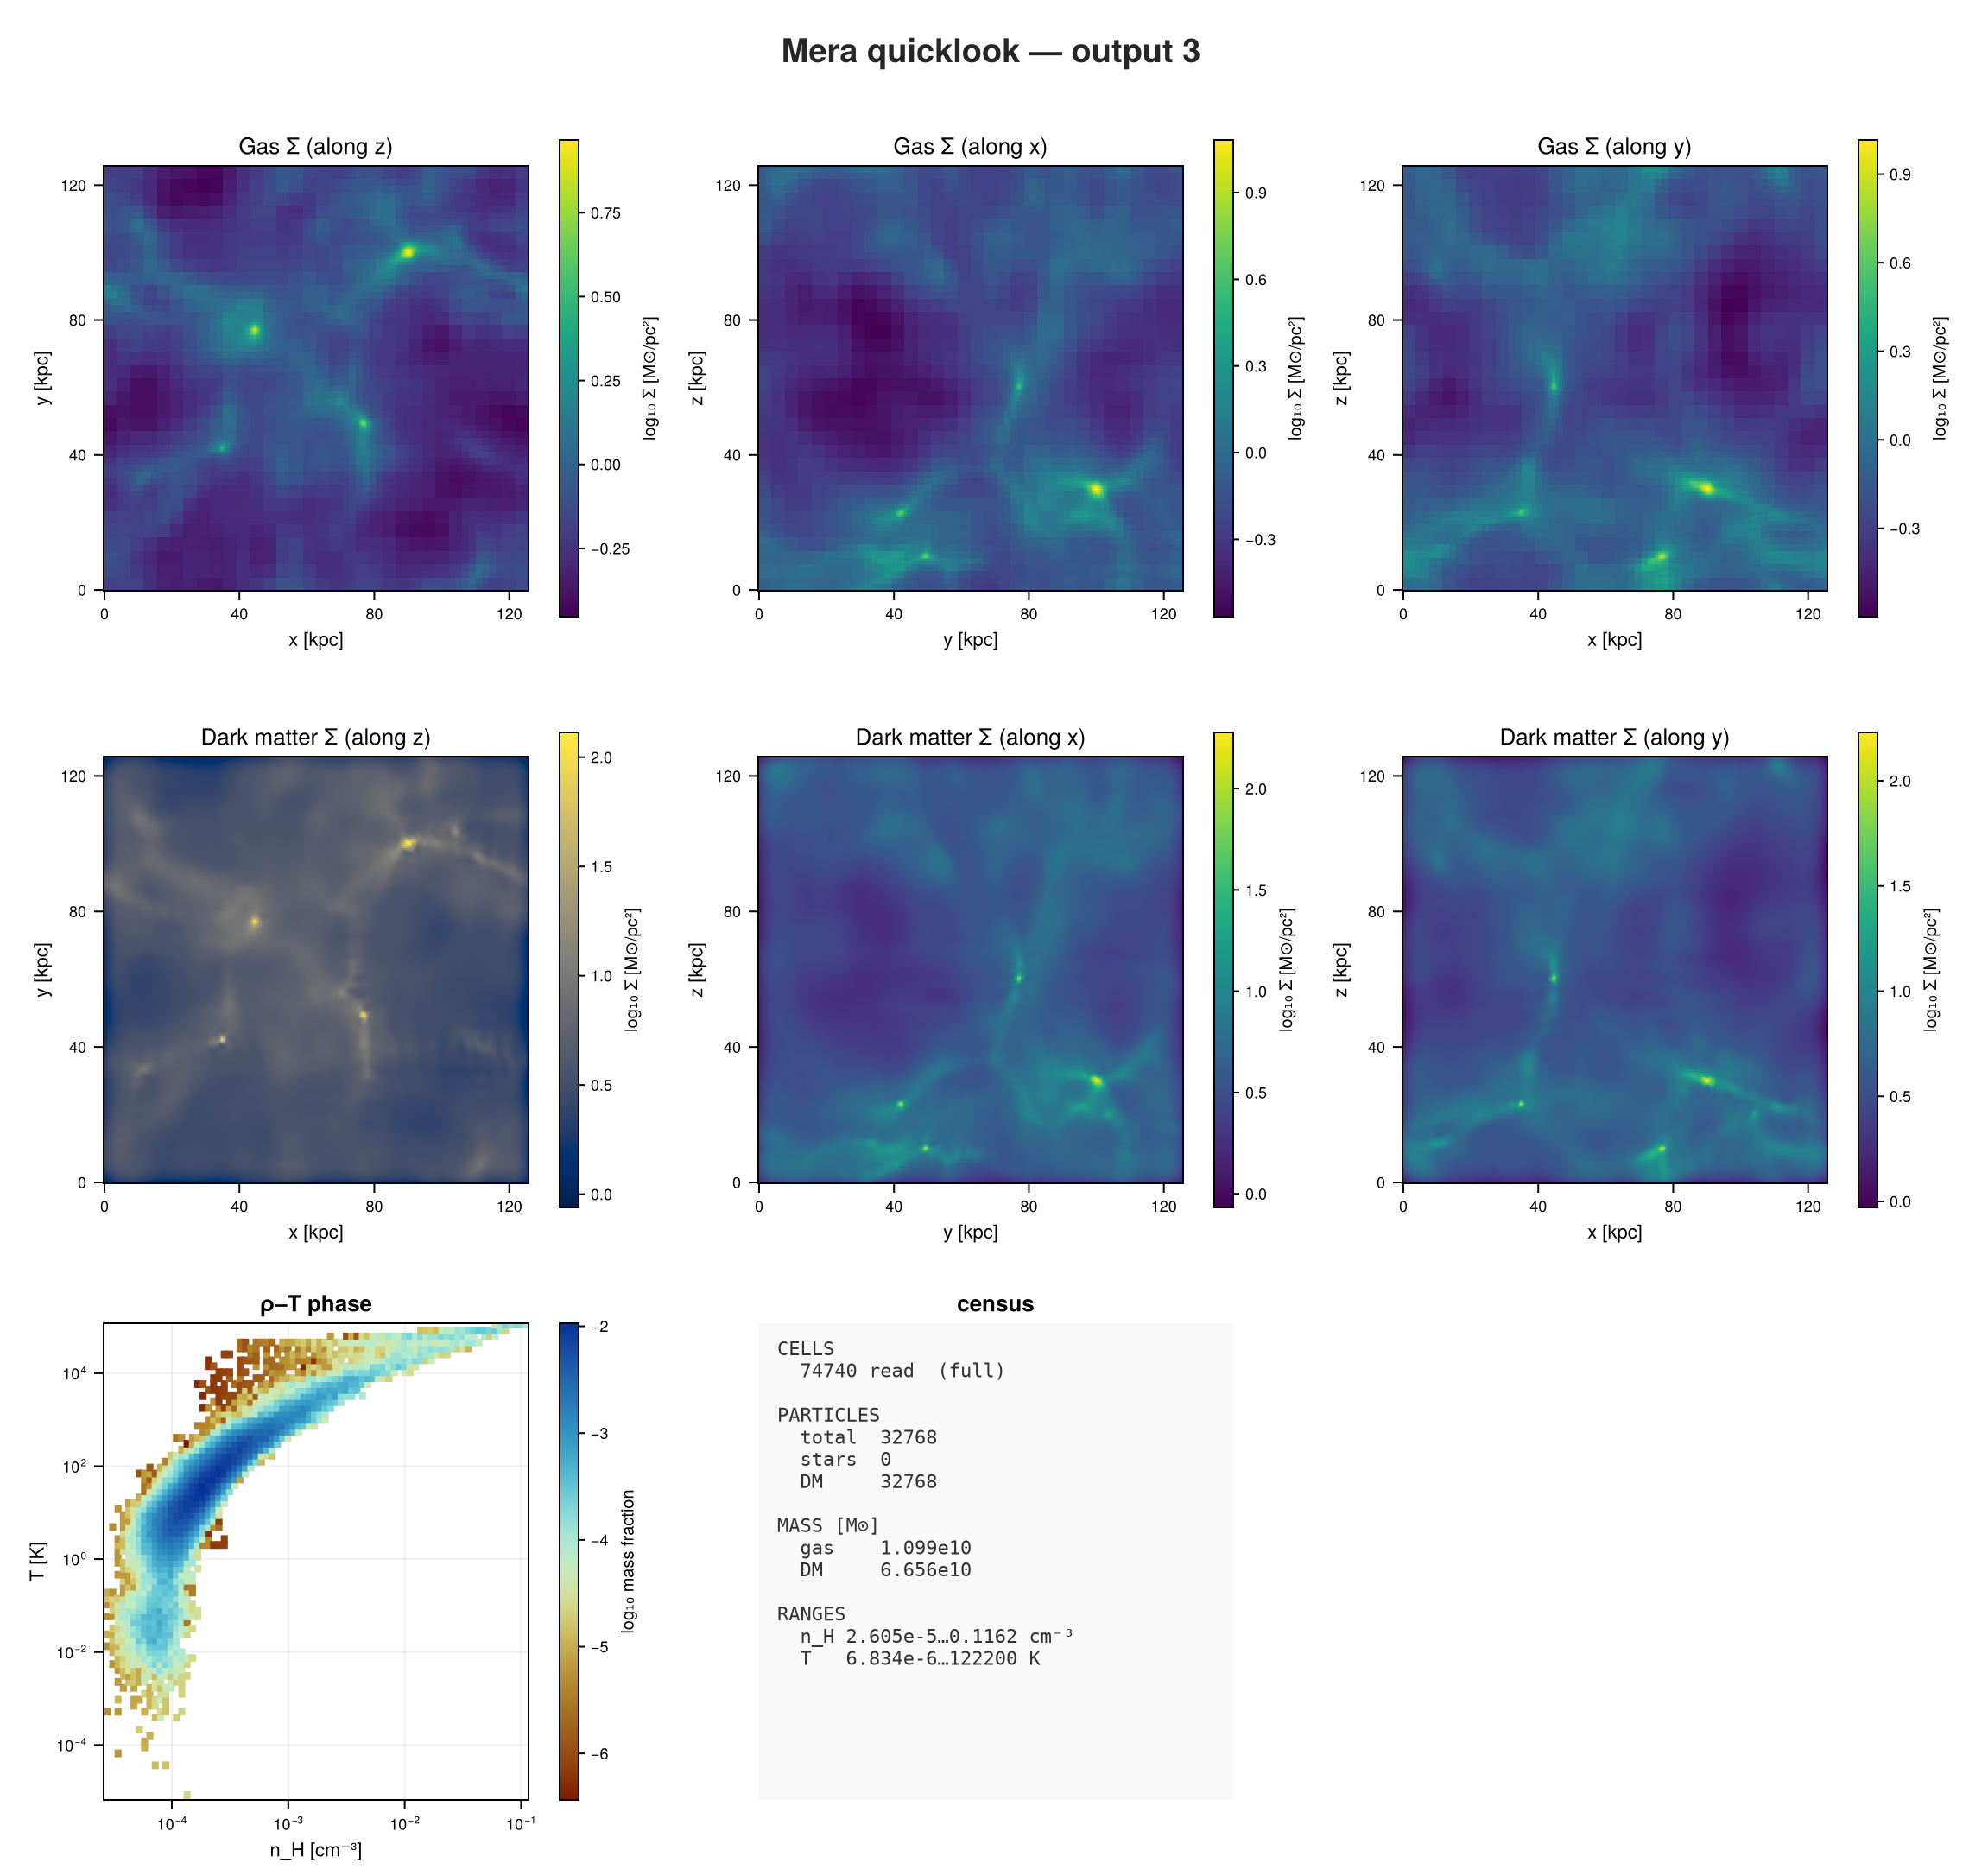

In [18]:
quicklookplot(look(3, "cosmo3d"))

## How long each first look took

Measured on the machine that built this page, with 8 threads. The first call includes compiling
the reader and the plots, which happens once per Julia session.

In [19]:
human(s) = s < 60 ? "$(round(s, sigdigits=2)) s" : "$(floor(Int, s / 60)) min $(round(Int, s % 60)) s"
println(rpad("simulation", 22), rpad("cells read", 13), "quicklook")
for (name, t, n) in TIMES
    println(rpad(name, 22), rpad(n, 13), human(t))
end

simulation            cells read   quicklook
sedov3d_amr           7071         10.0 s
sedov3d_bisection     7071         0.13 s
sedov3d_iogroups      6469         0.12 s
sedov3d_grav_part     7071         4.0 s
dm_gas3d_bisection    52466        2.5 s
sinks3d               262144       1.0 s
ramses_smbh_bondi     2097152      2.3 s
mhdtube3d             32768        0.92 s
ramses_abc_flow       32768        0.74 s
stromgren3d           32768        0.94 s
ramses_rt_dirac       25040        0.82 s
cosmo3d               74740        0.78 s


## Next steps

- [First Look](first_look.md): `quicklook` and `report` in depth, on a large galaxy run.
- [Composable Reports](report.md): all card types and their options.
- [Testing Framework](advanced_features/testing_guide.md): running the test suite these simulations
  back, and measuring its coverage.